# **STEP 0 - SetUp Environment & Train/Test**

In [1]:
!pip install pyagrum

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 26.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 90.7 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1


In [2]:
# ============================================================
# IMPORTS
# ============================================================
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, f1_score

# ============================================================
# STEP 0 — LOAD DATA
# ============================================================
data_folder_path = '/kaggle/input/cognitiveload/UBIcomp2020/last_30s_segments/'

label_df = pd.read_excel(data_folder_path+'labels.xlsx', index_col=0)
temp_df  = pd.read_excel(data_folder_path+'temp.xlsx', index_col=0)
hr_df    = pd.read_excel(data_folder_path+'hr.xlsx', index_col=0)
gsr_df   = pd.read_excel(data_folder_path+'gsr.xlsx', index_col=0)
rr_df    = pd.read_excel(data_folder_path+'rr.xlsx', index_col=0)

# ============================================================
# FIXED SUBJECT SPLIT
# ============================================================
train_ids = [
    '1mpau','2nxs5','5gpsc','7swyk','8a1ep','b7mrd',
    'c24ur','dkhty','e4gay','ef5rq','f3j25','hpbxa',
    'ibvx8','iz2ps','rc1in','tn4vl','wjxci','yljm5'
]

test_ids = ['3caqi','6frz4','bd47a','f1gjp','iz3x1']

X_train, y_train, user_train = [], [], []
X_test,  y_test,  user_test  = [], [], []

for user in label_df.user_id.unique():
    idx = label_df.user_id == user

    X_user = np.stack([
        temp_df[idx].values,
        hr_df[idx].values,
        gsr_df[idx].values,
        rr_df[idx].values
    ], axis=1)

    y = label_df.loc[idx, 'level'].values
    y[y == 'rest'] = -1
    y = y.astype(int) + 1
    y[y > 0] = 1   # binary: 0=Low, 1=High

    if user in train_ids:
        X_train.append(X_user)
        y_train.extend(y)
        user_train.extend(label_df.loc[idx,'user_id'].values)

    elif user in test_ids:
        X_test.append(X_user)
        y_test.extend(y)
        user_test.extend(label_df.loc[idx,'user_id'].values)

X_train = np.vstack(X_train)
X_test  = np.vstack(X_test)
y_train = np.array(y_train)
y_test  = np.array(y_test)
user_train = np.array(user_train)
user_test  = np.array(user_test)


In [3]:
import pandas as pd

user_counts = pd.Series(user_train).value_counts().sort_index()
print(user_counts)

print(sum(user_counts))

1mpau    38
2nxs5    39
5gpsc    41
7swyk    36
8a1ep    19
b7mrd    31
c24ur    39
dkhty    37
e4gay    38
ef5rq    38
f3j25    39
hpbxa    14
ibvx8    35
iz2ps    38
rc1in    38
tn4vl    35
wjxci    38
yljm5    39
Name: count, dtype: int64
632


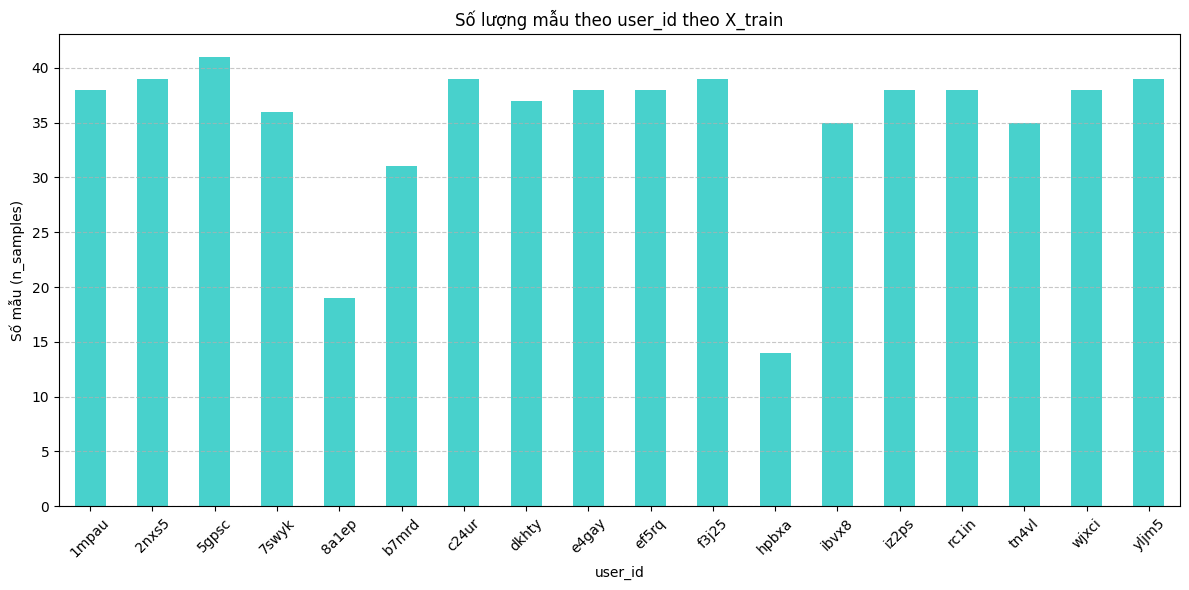

In [4]:
import matplotlib.pyplot as plt

# Giả sử bạn đã có user_counts như sau (đã sort_index)
# user_counts = df_train.groupby('user_id').size().sort_index()

plt.figure(figsize=(12, 6))

user_counts.plot(kind='bar', color='mediumturquoise')

plt.title('Số lượng mẫu theo user_id theo X_train')
plt.xlabel('user_id')
plt.ylabel('Số mẫu (n_samples)')
plt.xticks(rotation=45)  # xoay nhãn trục x cho dễ đọc
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.stats import skew, kurtosis, shapiro, kstest

signal_names = ["TEMP","HR","GSR","RR"]

def check_normality_raw(X, signal_names, max_samples=5000):
    """
    X: (N, 4, T)
    max_samples: số điểm dùng kiểm định Shapiro-Wilk (Shapiro <= 5000)
    """
    N, S, T = X.shape
    for j in range(S):  # loop qua từng tín hiệu
        sig_data = X[:, j, :].flatten()  # flatten tất cả các window time-series
        if len(sig_data) > max_samples:
            sig_data_sample = np.random.choice(sig_data, max_samples, replace=False)
        else:
            sig_data_sample = sig_data

        print(f"\n===== {signal_names[j]} =====")
        print(f"Data points: {len(sig_data)}")

        # Histogram
        plt.figure(figsize=(5,3))
        plt.hist(sig_data_sample, bins=50, color='skyblue', edgecolor='black')
        plt.title(f"Histogram of {signal_names[j]}")
        plt.show()

        # Q-Q Plot
        plt.figure(figsize=(5,5))
        stats.probplot(sig_data_sample, dist="norm", plot=plt)
        plt.title(f"Q-Q Plot of {signal_names[j]}")
        plt.show()

        # Skewness & Kurtosis
        s = skew(sig_data_sample)
        k = kurtosis(sig_data_sample)  # Fisher's definition
        print(f"Skewness: {s:.3f}, Kurtosis: {k:.3f}")

        # Shapiro-Wilk test
        stat, p = shapiro(sig_data_sample)
        print(f"Shapiro-Wilk p-value: {p:.4f}")
        if p > 0.05:
            print(" → Có thể là phân phối chuẩn")
        else:
            print(" → Không phải phân phối chuẩn")

        # Kolmogorov-Smirnov test
        stat, p = kstest(sig_data_sample, 'norm', args=(np.mean(sig_data_sample), np.std(sig_data_sample)))
        print(f"K-S test p-value: {p:.4f}")
        if p > 0.05:
            print(" → Có thể là phân phối chuẩn")
        else:
            print(" → Không phải phân phối chuẩn")



===== TEMP =====
Data points: 18960


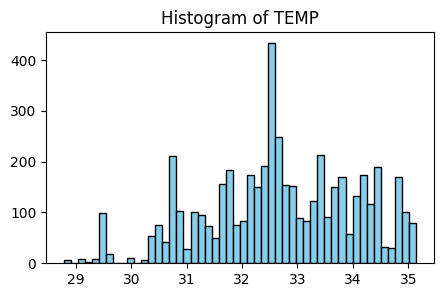

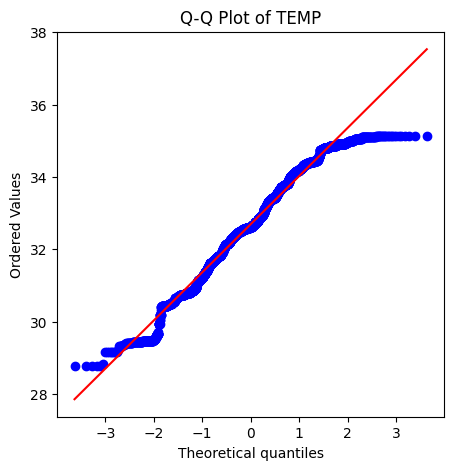

Skewness: -0.268, Kurtosis: -0.446
Shapiro-Wilk p-value: 0.0000
 → Không phải phân phối chuẩn
K-S test p-value: 0.0000
 → Không phải phân phối chuẩn

===== HR =====
Data points: 18960


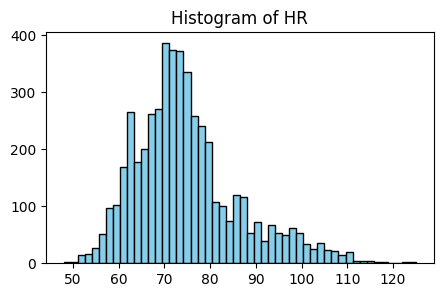

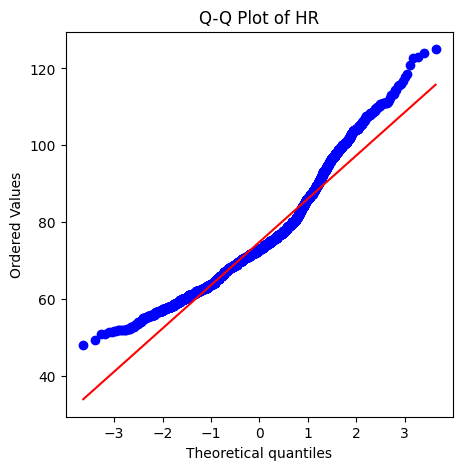

Skewness: 0.938, Kurtosis: 0.911
Shapiro-Wilk p-value: 0.0000
 → Không phải phân phối chuẩn
K-S test p-value: 0.0000
 → Không phải phân phối chuẩn

===== GSR =====
Data points: 18960


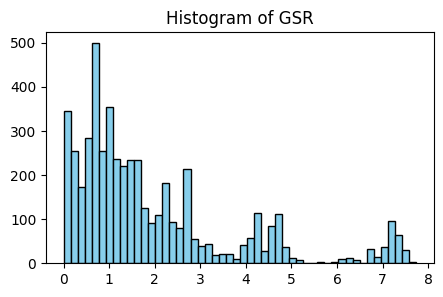

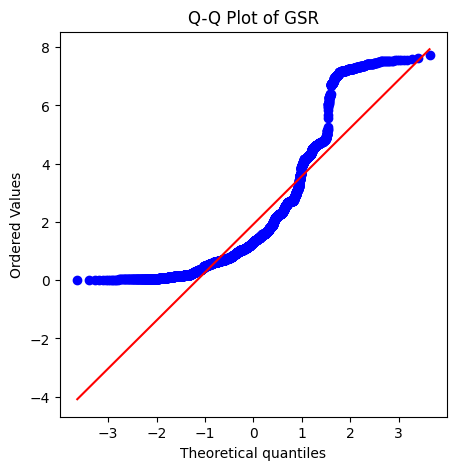

Skewness: 1.515, Kurtosis: 1.715
Shapiro-Wilk p-value: 0.0000
 → Không phải phân phối chuẩn
K-S test p-value: 0.0000
 → Không phải phân phối chuẩn

===== RR =====
Data points: 18960


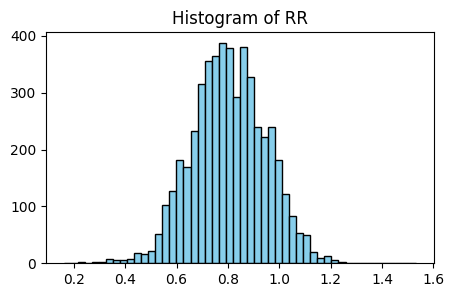

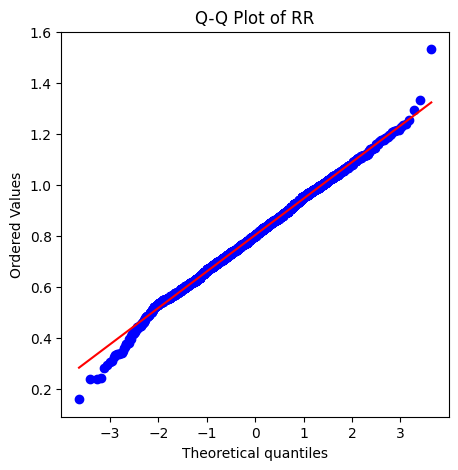

Skewness: -0.050, Kurtosis: 0.297
Shapiro-Wilk p-value: 0.0000
 → Không phải phân phối chuẩn
K-S test p-value: 0.2438
 → Có thể là phân phối chuẩn


In [6]:
check_normality_raw(X_train, signal_names)


# **STEP 1 - Feature Extraction**

In [7]:
import numpy as np
import pandas as pd

def extract_features(X):
    """
    X shape: (N, 4, T)
    Return: (N, 12)
    Features per signal: [mean, std, slope]
    Order: [TEMP, GSR, HR, RR]
    """
    # Mean
    mean_feat = X.mean(axis=2)          # (N, 4)

    # Standard deviation
    std_feat = X.std(axis=2)             # (N, 4)

    # Slope (linear trend)
    T = X.shape[2]
    t = np.arange(T)
    t = t - t.mean()                     # center time for stability

    slope_feat = np.zeros((X.shape[0], X.shape[1]))
    for i in range(X.shape[0]):          # samples
        for j in range(X.shape[1]):      # signals
            slope_feat[i, j] = np.polyfit(t, X[i, j], 1)[0]

    # Concatenate: (N, 12)
    features = np.concatenate(
        [mean_feat, std_feat, slope_feat],
        axis=1
    )

    return features
Xtr = extract_features(X_train)   # (N_train, 12)
Xte = extract_features(X_test)    # (N_test, 12)


columns = [
    # Mean
    "TEMP_mean", "HR_mean", "GSR_mean", "RR_mean",

    # Std
    "TEMP_std",  "HR_std",  "GSR_std",  "RR_std",

    # Slope
    "TEMP_slope","HR_slope","GSR_slope","RR_slope"
]


df_features = pd.DataFrame(Xtr, columns=columns)
df_features

,TEMP_mean,HR_mean,GSR_mean,RR_mean,TEMP_std,HR_std,GSR_std,RR_std,TEMP_slope,HR_slope,GSR_slope,RR_slope
0,30.729000,66.900000,0.135694,0.897627,0.003958,1.881981,0.002842,0.035447,0.000189,-0.027215,0.000327,-0.000511
1,30.911667,72.166667,0.171210,0.830337,0.003522,3.617601,0.006960,0.120333,-0.000277,-0.360771,0.000662,0.001668
2,31.044666,70.688889,0.171490,0.865734,0.012696,2.538494,0.011482,0.035377,0.000920,-0.250649,-0.000224,-0.000044
3,30.787334,66.088889,0.120144,0.900761,0.006348,3.498077,0.003313,0.040409,0.000460,0.254653,0.000045,-0.002067
4,30.761334,71.333333,0.219273,0.850063,0.003174,2.334920,0.001629,0.032631,-0.000230,-0.193252,0.000143,0.001264
...,...,...,...,...,...,...,...,...,...,...,...,...
627,34.157999,73.288889,2.918217,0.830706,0.017671,3.697580,0.018213,0.055332,-0.001676,-0.301520,-0.002059,0.003923
628,34.004667,70.016667,2.931450,0.894217,0.018649,3.083814,0.041350,0.075135,-0.001854,-0.257879,-0.001308,0.005766
629,33.786001,69.766667,2.647161,0.868868,0.018982,3.711993,0.007576,0.051633,-0.001916,-0.038932,-0.000794,-0.001613
630,34.080557,77.422222,2.877494,0.758900,0.002992,1.085027,0.019822,0.136341,-0.000108,-0.027735,0.001466,-0.000942


In [8]:
df_features.describe()

,TEMP_mean,HR_mean,GSR_mean,RR_mean,TEMP_std,HR_std,GSR_std,RR_std,TEMP_slope,HR_slope,GSR_slope,RR_slope
count,632.000000,632.000000,632.000000,632.000000,632.000000,632.000000,632.000000,632.000000,6.320000e+02,632.000000,632.000000,632.000000
mean,32.662296,74.986313,1.918875,0.804480,0.009249,2.859206,0.042404,0.076802,2.638646e-04,-0.023083,-0.000368,0.000594
std,1.338342,10.871879,1.801688,0.112983,0.010341,2.196671,0.064784,0.042918,1.249729e-03,0.287110,0.006164,0.004501
min,28.779890,54.622222,0.024615,0.495271,0.000000,0.366667,0.000259,0.005877,-6.488003e-03,-1.342455,-0.033757,-0.019341
25%,31.784917,67.725000,0.676193,0.726637,0.002577,1.490669,0.006748,0.043975,-2.462051e-04,-0.150704,-0.001511,-0.001650
50%,32.610334,72.894444,1.335896,0.804712,0.006348,2.333717,0.018777,0.068621,2.997577e-16,-0.009603,-0.000224,0.000220
75%,33.715500,79.961111,2.556066,0.885275,0.013253,3.507294,0.051045,0.099782,8.501811e-04,0.126288,0.000905,0.002735
max,35.138333,118.377778,7.595011,1.075346,0.067249,21.205255,0.723243,0.239776,6.862410e-03,1.679570,0.041788,0.021626


Raw signals

 → Feature extraction (mean, std, slope)
 
 → Feature-specific normalization
     • mean  → none
     • std   → log(x + ε)
     • slope → clip percentile
     
 → Gaussian membership functions
 
 → Membership degree ∈ [0,1]
 → Fuzzy inference / FBN / ANFIS


In [9]:
def preprocess_features(X, columns, eps=1e-6, clip_percentile=95):
    """
    Preprocess features according to fuzzy-semantic normalization rules

    Parameters
    ----------
    X : np.ndarray (N, 12)
        Extracted features [mean, std, slope]
    columns : list[str]
        Feature names
    eps : float
        Small constant for log transform
    clip_percentile : int
        Percentile for slope clipping

    Returns
    -------
    X_proc : np.ndarray (N, 12)
        Preprocessed features
    """

    X_proc = X.copy()

    for idx, name in enumerate(columns):

        # ===============================
        # MEAN FEATURES → NO NORMALIZATION
        # ===============================
        if name.endswith("_mean"):
            # giữ nguyên để bảo toàn ngữ nghĩa sinh lý
            continue

        # ===============================
        # STD FEATURES → LOG TRANSFORM
        # ===============================
        elif name.endswith("_std"):
            # đảm bảo không âm
            X_proc[:, idx] = np.log(X_proc[:, idx] + eps)

        # ===============================
        # SLOPE FEATURES → CLIP PERCENTILE
        # ===============================
        elif name.endswith("_slope"):
            p = np.percentile(np.abs(X_proc[:, idx]), clip_percentile)
            if p == 0:
                p = eps
            X_proc[:, idx] = np.clip(X_proc[:, idx], -p, p)

        else:
            raise ValueError(f"Unknown feature type: {name}")

    return X_proc
Xtr_proc = preprocess_features(Xtr, columns)
Xte_proc = preprocess_features(Xte, columns)


In [10]:
df_tr_proc = pd.DataFrame(Xtr_proc, columns=columns)
df_tr_proc.describe()


,TEMP_mean,HR_mean,GSR_mean,RR_mean,TEMP_std,HR_std,GSR_std,RR_std,TEMP_slope,HR_slope,GSR_slope,RR_slope
count,632.000000,632.000000,632.000000,632.000000,632.000000,632.000000,632.000000,632.000000,6.320000e+02,632.000000,632.000000,632.000000
mean,32.662296,74.986313,1.918875,0.804480,-6.569473,0.838599,-4.061741,-2.733431,2.526528e-04,-0.019596,-0.000357,0.000534
std,1.338342,10.871879,1.801688,0.112983,3.661317,0.639820,1.459343,0.606898,1.065165e-03,0.241772,0.004639,0.003977
min,28.779890,54.622222,0.024615,0.495271,-13.815511,-1.003299,-8.253116,-5.136537,-2.820949e-03,-0.560849,-0.013861,-0.009350
25%,31.784917,67.725000,0.676193,0.726637,-5.961533,0.399225,-4.998337,-3.124123,-2.462051e-04,-0.150704,-0.001511,-0.001650
50%,32.610334,72.894444,1.335896,0.804712,-5.059445,0.847462,-3.975052,-2.679144,2.997577e-16,-0.009603,-0.000224,0.000220
75%,33.715500,79.961111,2.556066,0.885275,-4.323426,1.254845,-2.975019,-2.304763,8.501811e-04,0.126288,0.000905,0.002735
max,35.138333,118.377778,7.595011,1.075346,-2.699333,3.054249,-0.324009,-1.428045,2.820949e-03,0.560849,0.013861,0.009350


# **STEP 2 — Initialization of Gaussian Membership Functions - (generate_gaussian_mfs_from_train)**

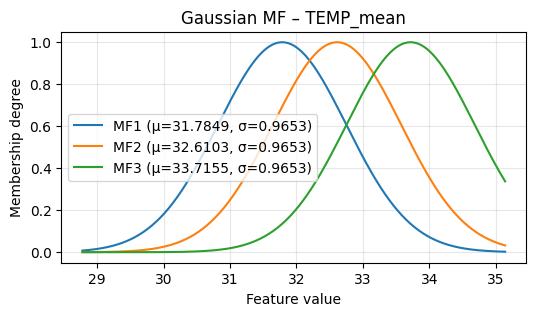

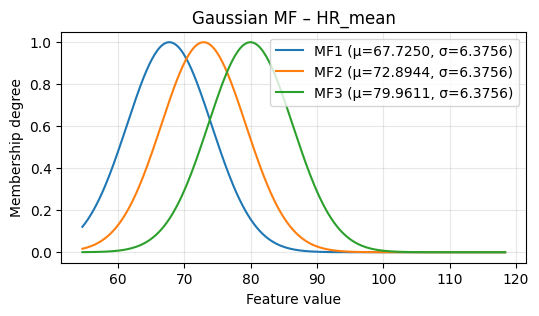

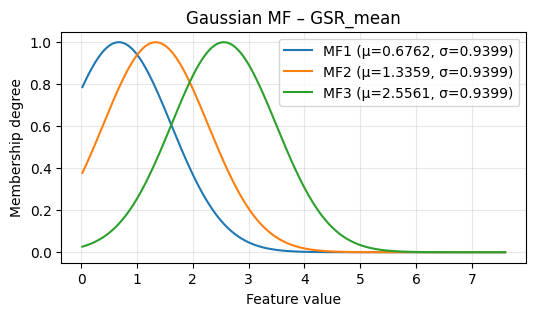

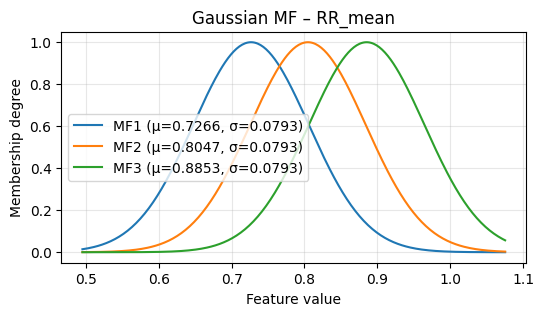

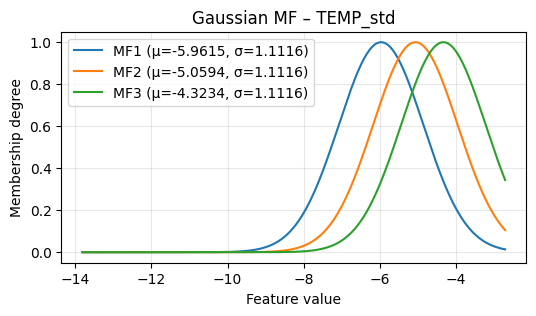

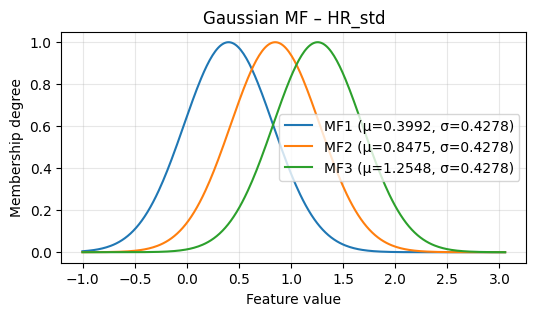

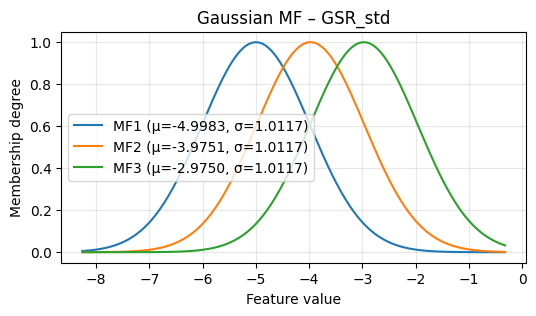

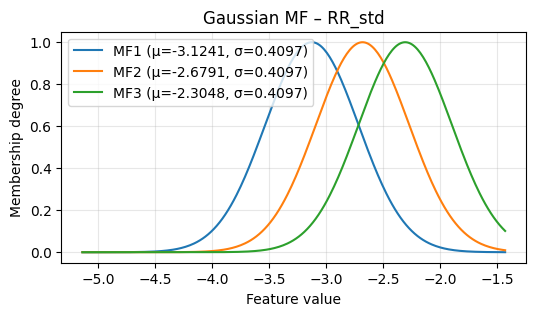

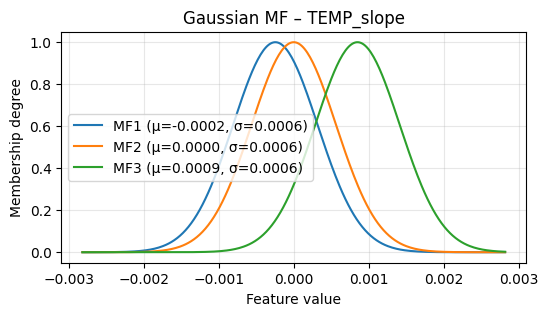

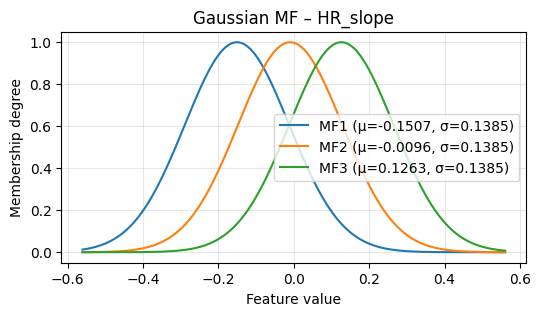

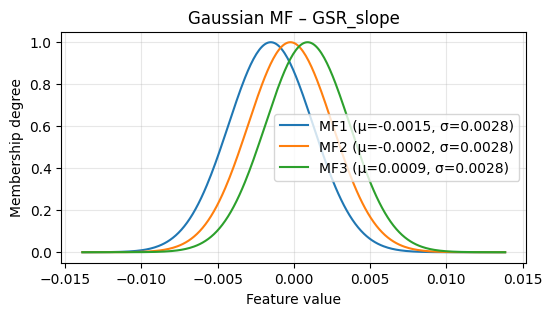

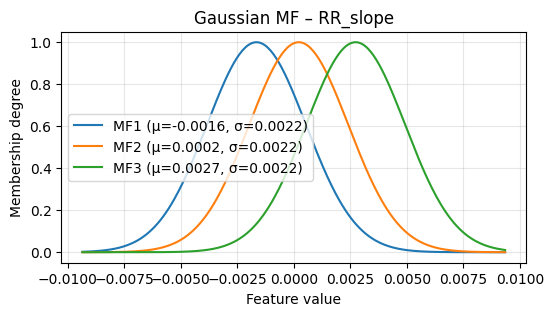

In [11]:
def generate_gaussian_mfs_from_train(
    Xtr_proc,
    columns,
    percentiles=(25, 50, 75),
    min_sigma_ratio=0.1,
    min_sigma_abs=1e-3  
):
    """
    Generate Gaussian MF parameters from preprocessed training data

    Parameters
    ----------
    Xtr_proc : np.ndarray (N, D)
        Preprocessed training features
    columns : list[str]
        Feature names
    percentiles : tuple
        Percentiles to place MF centers (μ)
    min_sigma_ratio : float
        Minimum sigma as ratio of feature range

    Returns
    -------
    mf_params : dict
        { feature_name : [ (mu1, sigma), (mu2, sigma), (mu3, sigma) ] }
    """

    mf_params = {}

    for i, name in enumerate(columns):
        data = Xtr_proc[:, i]

        # ---------- μ: percentile-based centers ----------
        mu_list = np.percentile(data, percentiles)

        # ---------- σ: robust width from IQR ----------
        q25, q75 = np.percentile(data, [25, 75])
        sigma = (q75 - q25) / 2.0

        # ---------- avoid σ too small ----------
        data_range = np.max(data) - np.min(data)
        min_sigma = min_sigma_ratio * data_range
        sigma = max(sigma, min_sigma, 1e-6)

        mf_params[name] = [(mu, sigma) for mu in mu_list]

    return mf_params
def gaussian_mf(x, mu, sigma):
    """
    Gaussian membership function
    """
    return np.exp(-0.5 * ((x - mu) / sigma) ** 2)
def plot_gaussian_mfs(Xtr_proc, columns, mf_params, n_points=300):
    """
    Plot Gaussian MF for each feature
    """
    for i, name in enumerate(columns):
        data = Xtr_proc[:, i]
        x = np.linspace(np.min(data), np.max(data), n_points)

        plt.figure(figsize=(6, 3))
        for j, (mu, sigma) in enumerate(mf_params[name]):
            y = gaussian_mf(x, mu, sigma)
            plt.plot(x, y, label=f"MF{j+1} (μ={mu:.4f}, σ={sigma:.4f})")

        plt.title(f"Gaussian MF – {name}")
        plt.xlabel("Feature value")
        plt.ylabel("Membership degree")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.show()
mf_params = generate_gaussian_mfs_from_train(
    Xtr_proc,
    columns,
    percentiles=(25, 50, 75),
    min_sigma_ratio=0.1
)

plot_gaussian_mfs(Xtr_proc, columns, mf_params)


# **STEP 2.1 — generate_gaussian_mfs_from_train**

**Membership values (độ thành viên)**

In [12]:
def fuzzify(X, mf_params, columns):
    """
    Chuyển đặc trưng input thành membership values với các Gaussian MF

    X: np.ndarray (N, D)
    mf_params: dict {feature_name: [(mu, sigma), ...]}
    columns: list tên feature theo thứ tự cột trong X

    Return:
    memberships: np.ndarray (N, D * n_mf)
    """
    n_samples = X.shape[0]
    n_features = X.shape[1]
    n_mf = len(next(iter(mf_params.values())))  # số MF, vd 3

    memberships = np.zeros((n_samples, n_features * n_mf))

    for i, name in enumerate(columns):
        for j, (mu, sigma) in enumerate(mf_params[name]):
            memberships[:, i*n_mf + j] = gaussian_mf(X[:, i], mu, sigma)

    return memberships

# Ví dụ fuzzify tập train
Xtr_fuzzy = fuzzify(Xtr_proc, mf_params, columns)
print("Shape membership fuzzy features:", Xtr_fuzzy.shape)  
# Nếu có 12 feature, 3 MF mỗi feature => shape sẽ là (N_samples, 36)

# Tạo tên cột chi tiết cho membership features
mf_names = ['MF1', 'MF2', 'MF3']
fuzzy_columns = []
for feat in columns:
    for mf in mf_names:
        fuzzy_columns.append(f"{feat}_{mf}")

# Tạo DataFrame fuzzy membership với tên cột rõ ràng
df_Xtr_fuzzy = pd.DataFrame(Xtr_fuzzy, columns=fuzzy_columns)

df_Xtr_fuzzy


Shape membership fuzzy features: (632, 36)


,TEMP_mean_MF1,TEMP_mean_MF2,TEMP_mean_MF3,HR_mean_MF1,HR_mean_MF2,HR_mean_MF3,GSR_mean_MF1,GSR_mean_MF2,GSR_mean_MF3,RR_mean_MF1,...,TEMP_slope_MF3,HR_slope_MF1,HR_slope_MF2,HR_slope_MF3,GSR_slope_MF1,GSR_slope_MF2,GSR_slope_MF3,RR_slope_MF1,RR_slope_MF2,RR_slope_MF3
0,0.549749,0.149679,0.008345,0.991663,0.642743,0.122649,0.847610,0.442536,0.036319,0.097923,...,5.033348e-01,0.671990,0.991947,0.541057,0.802754,0.980415,0.978529,0.873713,0.946052,0.334286
1,0.664184,0.212598,0.014721,0.784526,0.993506,0.473636,0.865611,0.464080,0.040002,0.425445,...,1.360991e-01,0.316545,0.040173,0.002063,0.735493,0.950129,0.996190,0.318156,0.803887,0.888356
2,0.745244,0.268371,0.021758,0.897575,0.941918,0.347305,0.865749,0.464251,0.040032,0.214894,...,9.924768e-01,0.770758,0.219901,0.024633,0.897956,1.000000,0.920414,0.764808,0.992782,0.447744
3,0.586248,0.168081,0.010043,0.967609,0.565684,0.093747,0.839470,0.433227,0.034800,0.089858,...,7.870931e-01,0.013798,0.161976,0.650821,0.854304,0.995287,0.953074,0.982069,0.580531,0.090849
4,0.569947,0.159687,0.009251,0.852010,0.970467,0.400254,0.888558,0.493790,0.045484,0.297995,...,1.600263e-01,0.953908,0.415132,0.069836,0.836985,0.991249,0.962983,0.413602,0.892837,0.798311
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
627,0.048709,0.276565,0.900262,0.683318,0.998088,0.578328,0.058145,0.242446,0.928462,0.422862,...,4.438098e-05,0.552719,0.108466,0.008474,0.980656,0.803415,0.564815,0.039579,0.240273,0.863659
628,0.071076,0.352309,0.956122,0.937442,0.903147,0.296279,0.056219,0.236744,0.923348,0.107335,...,1.028632e-05,0.741250,0.200528,0.021341,0.997331,0.926454,0.727241,0.003280,0.040780,0.384658
629,0.116631,0.476309,0.997336,0.950018,0.886620,0.278487,0.110966,0.377913,0.995315,0.200352,...,6.013593e-06,0.722052,0.977827,0.490870,0.967124,0.979122,0.828880,0.999858,0.705178,0.139950
630,0.059138,0.313518,0.930985,0.314516,0.777108,0.923772,0.064415,0.260546,0.943206,0.920610,...,2.367536e-01,0.674235,0.991467,0.538810,0.561903,0.830373,0.979710,0.949191,0.869095,0.245057


In [13]:
df_Xtr_fuzzy.describe()

,TEMP_mean_MF1,TEMP_mean_MF2,TEMP_mean_MF3,HR_mean_MF1,HR_mean_MF2,HR_mean_MF3,GSR_mean_MF1,GSR_mean_MF2,GSR_mean_MF3,RR_mean_MF1,...,TEMP_slope_MF3,HR_slope_MF1,HR_slope_MF2,HR_slope_MF3,GSR_slope_MF1,GSR_slope_MF2,GSR_slope_MF3,RR_slope_MF1,RR_slope_MF2,RR_slope_MF3
count,632.000000,632.000000,632.000000,6.320000e+02,6.320000e+02,6.320000e+02,6.320000e+02,6.320000e+02,6.320000e+02,632.000000,...,6.320000e+02,632.000000,632.000000,632.000000,6.320000e+02,632.000000,6.320000e+02,632.000000,632.000000,6.320000e+02
mean,0.485522,0.567631,0.488989,5.337087e-01,5.695740e-01,4.046308e-01,5.904496e-01,6.015481e-01,3.562739e-01,0.474682,...,3.966428e-01,0.430191,0.544478,0.466424,6.565877e-01,0.703532,6.600153e-01,0.455313,0.531538,4.276113e-01
std,0.350428,0.348564,0.348002,3.628825e-01,3.666820e-01,3.343597e-01,3.910148e-01,3.448444e-01,3.284458e-01,0.351772,...,3.357730e-01,0.350627,0.371976,0.366014,3.563093e-01,0.367025,3.482860e-01,0.362846,0.374209,3.580259e-01
min,0.002395,0.000381,0.000002,1.965878e-14,8.880953e-12,1.305571e-08,1.714778e-12,2.349392e-10,5.744502e-07,0.000064,...,6.397696e-10,0.000002,0.000207,0.000005,2.106380e-07,0.000002,6.912578e-07,0.000003,0.000073,2.528959e-07
25%,0.116257,0.198339,0.135335,1.532055e-01,2.032873e-01,6.799739e-02,1.353581e-01,3.853488e-01,8.646923e-02,0.122167,...,7.216788e-02,0.079623,0.151833,0.074192,3.602821e-01,0.448838,4.097514e-01,0.074250,0.124896,5.768562e-02
50%,0.534733,0.610937,0.493736,6.145108e-01,6.637527e-01,3.633381e-01,7.816842e-01,7.002585e-01,2.285461e-01,0.453602,...,3.212991e-01,0.390417,0.610631,0.462525,8.434707e-01,0.904892,8.250950e-01,0.417317,0.598129,3.632502e-01
75%,0.790462,0.943765,0.817117,8.652258e-01,9.385370e-01,6.833178e-01,9.395747e-01,9.221528e-01,5.952544e-01,0.825593,...,6.954269e-01,0.765493,0.924944,0.827852,9.320405e-01,0.991973,9.454284e-01,0.809044,0.911867,7.837410e-01
max,1.000000,1.000000,0.999999,9.999991e-01,9.999692e-01,9.999966e-01,9.999999e-01,9.999978e-01,9.999812e-01,0.999994,...,9.997665e-01,0.999999,0.999996,1.000000,9.999997e-01,1.000000,9.999973e-01,1.000000,1.000000,1.000000e+00


# **ANFIS-based MF Parameter Optimization**

# ========HELLO===========

# IMPORT & SETUP

In [14]:
import copy, numpy as np, torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score


# ⚙️ HYPERPARAMETERS

In [15]:
N_SPLITS = 5
NUM_EPOCHS = 60
PATIENCE = 10
MIN_DELTA = 1e-4
BATCH_SIZE = 32
LR = 0.01
SEED = 42


# 🔹 MF INITIALIZATION (GIỮ NGUYÊN – ĐÚNG)

In [16]:
# 0️⃣ FIX RANDOMNESS – SEED
import torch
import numpy as np
import random
import os

def set_seed(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)


# EVALUATION (LOSS LÀ CHÍNH – ACC/F1 ĐỂ REPORT)

# STEP 1️⃣: GROUP-KFOLD CV – TÌM best_epoch

# STEP 2️⃣: TRAIN FINAL TRÊN ALL TRAIN → TEST

# 📈 REPORT CUỐI CÙNG

# THAM SỐ TỐI ƯU SAU KHI ĐIỀU CHỈNH BẰNG ANFIS

**Lưu ANFIS parameters + Linear layer**

**Lưu metrics / best epoch / per-user accuracy ra CSV**

**LOAD file**

# ================HI===================================

**Mô hình huấn luyện, tối ưu μ, σ**

=================================

# **STEP 4 — FUZZIFICATION (using optimized MF)**

# 1️⃣ Chuẩn bị membership từ ANFIS (sau khi train xong)

# 2️⃣ Chuẩn hóa memberships (soft evidence)

Code FBN yêu cầu mỗi feature 3 MF sum = 1. Dùng hàm normalize_fuzzy:

In [37]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, brier_score_loss, confusion_matrix

# ============================================================
# STEP 4 — LEARN FUZZY CPT (soft evidence)
# ============================================================
STATE_LVL = ["Low", "Medium", "High"]  # rename for slope if you want (Down/Stable/Up), but keep 3 states.

In [38]:

def normalize_fuzzy(X_fuzzy, n_mf=3, eps=1e-9):
    """
    Ensure each feature's 3 memberships sum to 1 (soft evidence).
    X_fuzzy: (N, D*n_mf)
    """
    X = X_fuzzy.copy()
    D = X.shape[1] // n_mf
    for i in range(D):
        block = X[:, i*n_mf:(i+1)*n_mf]
        s = block.sum(axis=1, keepdims=True)
        X[:, i*n_mf:(i+1)*n_mf] = block / (s + eps)
    return X

In [39]:
# Xtr_fuzzy_n = normalize_fuzzy(Xtr_proc,n_mf=3)
# Xte_fuzzy_n = normalize_fuzzy(Xte_proc, n_mf=3)

# # fuzzify first
Xtr_fuzzy = fuzzify(Xtr_proc, mf_params, columns)
Xte_fuzzy = fuzzify(Xte_proc, mf_params, columns)

# then normalize memberships
Xtr_fuzzy_n = normalize_fuzzy(Xtr_fuzzy, n_mf=3)
Xte_fuzzy_n = normalize_fuzzy(Xte_fuzzy, n_mf=3)

# Xtr_fuzzy_n = normalize_fuzzy(X_train_fuzzy, n_mf=3)
# Xte_fuzzy_n = normalize_fuzzy(X_test_fuzzy, n_mf=3)



# **3️⃣ Cross-validation / CPT learning******

ANFIS: GroupKFold để train neural-fuzzy model → tìm MF tốt

FBN: GroupKFold để đánh giá CPT và soft evidence → đo ổn định probabilistic model

Hai việc này khác nhau về mục đích → code fold khác nhau là hợp lý.

In [40]:
def learn_fuzzy_cpt_soft(X_fuzzy, y, columns, n_mf=3, alpha=1.0, return_df=True):
    """
    Learn CPT: P(state | class) using soft counts.
    cpt[feat][cls] = (3,) distribution over states.
    """
    y = np.asarray(y).astype(int)
    cpt = {}
    rows = []

    for i, feat in enumerate(columns):
        mu_feat = X_fuzzy[:, i*n_mf:(i+1)*n_mf]  # (N,3)
        cpt[feat] = {}

        for cls in [0, 1]:
            mask = (y == cls)
            counts = mu_feat[mask].sum(axis=0) + alpha
            probs = counts / (counts.sum() + 1e-12)
            cpt[feat][cls] = probs

            if return_df:
                row = {"Feature": feat, "Class": cls}
                for lbl, p in zip(STATE_LVL, probs):
                    row[lbl] = float(p)
                rows.append(row)

    df = pd.DataFrame(rows) if return_df else None
    return cpt, df


In [41]:
# (Optional) FWBC-like score để biết node/state nào "mạnh" (tham khảo Eq.8 paper)
def fwbc_state_to_class(X_fuzzy, y, columns, n_mf=3, alpha=1e-6):
    """
    FWBC(feat_state -> CL=1) = Support(feat_state, CL=1) / Support(feat_state)
    Support dùng soft membership.
    """
    y = np.asarray(y).astype(int)
    out = []

    for i, feat in enumerate(columns):
        mu = X_fuzzy[:, i*n_mf:(i+1)*n_mf]  # (N,3)
        sup_state = mu.sum(axis=0) + alpha
        sup_state_task = mu[y == 1].sum(axis=0) + alpha
        fwbc = sup_state_task / sup_state

        for s, name in enumerate(STATE_LVL):
            out.append({
                "Feature": feat,
                "State": name,
                "Support": float(sup_state[s]),
                "FWBC_Task": float(fwbc[s])  # gần 1 => state này hay xuất hiện trong Task
            })

    return pd.DataFrame(out).sort_values("FWBC_Task", ascending=False)


In [42]:

# ============================================================
# STEP 5 — BAYESIAN INFERENCE WITH FUZZY EVIDENCE (debug print inside for)
# ============================================================
def predict_fbn_proba_debug(
    X_fuzzy, cpt, priors, columns, n_mf=3, eps=1e-9,
    debug=False, debug_samples=(0,), topk=6
):
    """
    Returns:
      probs:   (N,2)
      contrib: (N,D) contribution to log-odds (Task - Rest) per feature
    """

    N = X_fuzzy.shape[0]
    D = len(columns)

    log_scores = np.zeros((N, 2), dtype=float)
    contrib = np.zeros((N, D), dtype=float)

    # ---------- log-likelihood ----------
    for cls in (0, 1):
        logp = np.full(N, np.log(priors[cls] + eps))

        for i, feat in enumerate(columns):
            mu = X_fuzzy[:, i*n_mf:(i+1)*n_mf]      # (N,3)
            like = mu @ cpt[feat][cls]              # (N,)
            logp += np.log(like + eps)

        log_scores[:, cls] = logp

    # ---------- per-feature contribution (interpretability) ----------
    for i, feat in enumerate(columns):
        mu = X_fuzzy[:, i*n_mf:(i+1)*n_mf]
        like0 = mu @ cpt[feat][0]
        like1 = mu @ cpt[feat][1]
        contrib[:, i] = np.log(like1 + eps) - np.log(like0 + eps)

    # ---------- SAFE normalization (NO if-else) ----------
    log_scores -= log_scores.max(axis=1, keepdims=True)  # stability
    exp_scores = np.exp(log_scores)

    den = exp_scores.sum(axis=1, keepdims=True)

    probs = np.divide(
        exp_scores,
        den,
        out=np.full_like(exp_scores, 0.5),  # fallback: ignorance prior
        where=den > 0
    )

    # ---------- DEBUG PRINT ----------
    if debug:
        for idx in debug_samples:
            print("=" * 80)
            print(f"[DEBUG] Sample {idx}")
            print(f"Prior: P(Rest)={priors[0]:.3f}, P(Task)={priors[1]:.3f}")
            print(f"Posterior: P(Rest)={probs[idx,0]:.3f}, P(Task)={probs[idx,1]:.3f}")
            print("-" * 80)

            rows = []
            for i, feat in enumerate(columns):
                mu = X_fuzzy[idx, i*n_mf:(i+1)*n_mf]
                like0 = float(mu @ cpt[feat][0])
                like1 = float(mu @ cpt[feat][1])
                delta = float(np.log(like1 + eps) - np.log(like0 + eps))

                rows.append({
                    "Feature": feat,
                    "mu(L,M,H)": np.round(mu, 4),
                    "like(Rest)": round(like0, 6),
                    "like(Task)": round(like1, 6),
                    "logΔ(Task-Rest)": round(delta, 6),
                })

            df_dbg = (
                pd.DataFrame(rows)
                .sort_values("logΔ(Task-Rest)", ascending=False)
            )

            print(df_dbg.head(topk).to_string(index=False))
            print("-" * 80)
            print("Top drivers (positive => Task, negative => Rest)")

    return probs, contrib


In [43]:
def evaluate_from_proba(P, y_true, thr=0.5):
    y_true = np.asarray(y_true).astype(int)
    p_task = P[:, 1]
    y_pred = (p_task >= thr).astype(int)

    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, p_task) if len(np.unique(y_true)) > 1 else np.nan
    brier = brier_score_loss(y_true, p_task)
    cm = confusion_matrix(y_true, y_pred)

    return {
        "acc": acc, "f1": f1, "auc": auc, "brier": brier,
        "cm": cm, "thr": thr
    }


In [44]:

# ============================================================
# STEP 6 — GROUPKFOLD ON TRAIN (choose alpha / threshold, and get CPT stability)
# ============================================================
def groupkfold_cv_fbn(Xtr_fuzzy, y_train, user_train, columns, n_mf=3,
                      n_splits=5, alpha=1.0, thr=0.5, eps=1e-9):
    gkf = GroupKFold(n_splits=n_splits)

    fold_metrics = []
    cpt_rows_all = []
    f1_scores = []

    for fold, (tr, va) in enumerate(gkf.split(Xtr_fuzzy, y_train, groups=user_train), start=1):
        X_tr, X_va = Xtr_fuzzy[tr], Xtr_fuzzy[va]
        y_tr, y_va = y_train[tr], y_train[va]

        priors = {0: float(np.mean(y_tr == 0)), 1: float(np.mean(y_tr == 1))}
        cpt, df_cpt = learn_fuzzy_cpt_soft(X_tr, y_tr, columns, n_mf=n_mf, alpha=alpha, return_df=True)

        P_va, _ = predict_fbn_proba_debug(X_va, cpt, priors, columns, n_mf=n_mf, eps=eps, debug=False)
        m = evaluate_from_proba(P_va, y_va, thr=thr)
        m["fold"] = fold
        fold_metrics.append(m)

        f1_scores.append(m["f1"])

        # store CPT rows for mean±std table
        df_cpt["fold"] = fold
        cpt_rows_all.append(df_cpt)

    df_metrics = pd.DataFrame([{
        "fold": m["fold"],
        "acc": m["acc"],
        "f1": m["f1"],
        "auc": m["auc"],
        "brier": m["brier"],
    } for m in fold_metrics])

    df_cpt_all = pd.concat(cpt_rows_all, ignore_index=True)

    # mean ± std per Feature-Class-State
    summary = (df_cpt_all
               .groupby(["Feature", "Class"])[STATE_LVL]
               .agg(["mean", "std"])
               .reset_index())

    # make it look like your screenshot: "0.313 ± 0.015"
    pretty = []
    for _, row in summary.iterrows():
        out = {"Feature": row[("Feature", "")] if ("Feature","") in row else row["Feature"],
               "Class":   row[("Class", "")] if ("Class","") in row else row["Class"]}
        for s in STATE_LVL:
            mu = row[(s, "mean")]
            sd = row[(s, "std")]
            out[s] = f"{mu:.3f} ± {sd:.3f}"
        pretty.append(out)
    df_cpt_pretty = pd.DataFrame(pretty)

    return df_metrics, df_cpt_pretty

In [45]:
# 1) GroupKFold CV để xem metrics ổn định
df_cv, df_cpt_meanstd = groupkfold_cv_fbn(
    Xtr_fuzzy_n, np.asarray(y_train), np.asarray(user_train),
    columns, n_mf=3, n_splits=5, alpha=1.0, thr=0.5
)

print("CV metrics:")
print(df_cv)
print("\nCPT mean±std (like your table):")
print(df_cpt_meanstd)


CV metrics:
   fold       acc        f1       auc     brier
0     1  0.531250  0.473684  0.533969  0.260581
1     2  0.713043  0.707965  0.745312  0.218862
2     3  0.640351  0.616822  0.654971  0.233471
3     4  0.643939  0.684564  0.649219  0.235895
4     5  0.650350  0.632353  0.707160  0.226087

CPT mean±std (like your table):
       Feature  Class            Low         Medium           High
0     GSR_mean      0  0.323 ± 0.032  0.321 ± 0.022  0.356 ± 0.051
1     GSR_mean      1  0.324 ± 0.033  0.321 ± 0.021  0.355 ± 0.052
2    GSR_slope      0  0.351 ± 0.012  0.309 ± 0.007  0.339 ± 0.009
3    GSR_slope      1  0.335 ± 0.007  0.328 ± 0.002  0.337 ± 0.006
4      GSR_std      0  0.310 ± 0.032  0.307 ± 0.010  0.382 ± 0.034
5      GSR_std      1  0.388 ± 0.022  0.326 ± 0.009  0.286 ± 0.018
6      HR_mean      0  0.331 ± 0.036  0.320 ± 0.017  0.349 ± 0.051
7      HR_mean      1  0.336 ± 0.039  0.302 ± 0.019  0.362 ± 0.057
8     HR_slope      0  0.387 ± 0.021  0.288 ± 0.011  0.325 ± 0.0

# 4️⃣ Final train → test

Dùng membership đã học, CPT học từ toàn bộ train:

In [46]:
# ============================================================
# STEP 7 — FINAL TRAIN → TEST (and print meaningful inference for a few samples)
# ============================================================
def final_train_test_fbn(Xtr_fuzzy, Xte_fuzzy, y_train, y_test, columns,
                         n_mf=3, alpha=1.0, thr=0.5, eps=1e-9,
                         debug_samples=(0,1,2)):
    priors = {0: float(np.mean(y_train == 0)), 1: float(np.mean(y_train == 1))}
    cpt, df_cpt = learn_fuzzy_cpt_soft(Xtr_fuzzy, y_train, columns, n_mf=n_mf, alpha=alpha, return_df=True)

    # DEBUG: print inside loops for chosen samples (this is what you asked)
    P_te, contrib = predict_fbn_proba_debug(
        Xte_fuzzy, cpt, priors, columns, n_mf=n_mf, eps=eps,
        debug=True, debug_samples=debug_samples, topk=8
    )

    metrics = evaluate_from_proba(P_te, y_test, thr=thr)
    return cpt, df_cpt, P_te, contrib, metrics

In [47]:
cpt_final, df_cpt_final, P_te, contrib_te, m = final_train_test_fbn(
    Xtr_fuzzy_n, Xte_fuzzy_n,
    np.asarray(y_train), np.asarray(y_test),
    columns, n_mf=3, alpha=1.0, thr=0.5,
    debug_samples=(0,1,2)
)

print("\nFINAL TEST:")
print("Accuracy:", m["acc"])
print("F1:", m["f1"])
print("AUC:", m["auc"])
print("Brier:", m["brier"])
print("Confusion matrix:\n", m["cm"])


[DEBUG] Sample 0
Prior: P(Rest)=0.502, P(Task)=0.498
Posterior: P(Rest)=0.320, P(Task)=0.680
--------------------------------------------------------------------------------
   Feature                mu(L,M,H)  like(Rest)  like(Task)  logΔ(Task-Rest)
    RR_std  [0.681, 0.2694, 0.0495]    0.288094    0.386831         0.294700
   GSR_std [0.6074, 0.3264, 0.0662]    0.314168    0.361193         0.139485
TEMP_slope [0.0166, 0.0568, 0.9266]    0.329456    0.375570         0.131004
    HR_std [0.8371, 0.1506, 0.0122]    0.316688    0.360283         0.128973
  HR_slope [0.1912, 0.4403, 0.3685]    0.320570    0.334812         0.043470
   RR_mean [0.0928, 0.3648, 0.5424]    0.328173    0.336850         0.026094
  TEMP_std  [0.1462, 0.3698, 0.484]    0.351432    0.356776         0.015094
  RR_slope  [0.208, 0.4297, 0.3623]    0.328531    0.329753         0.003713
--------------------------------------------------------------------------------
Top drivers (positive => Task, negative => Rest)
[DE

In [48]:
# plt.plot(range(1, 6), f1_scores, marker='o')
# plt.xlabel("Fold")
# plt.ylabel("F1-score")
# plt.title("F1 per Fold")
# plt.ylim(0, 1)
# plt.grid(True)
# plt.show()
# # In ra các giá trị F1 cụ thể
# for i, score in enumerate(f1_scores, start=1):
#     print(f"Fold {i}: F1-score = {score:.4f}")

# **** Từ Fold-wise line plot kết luận = > mô hình ổn định ko bị overfitting ****

In [49]:
print("Xtr_fuzzy_n.shape:", Xtr_fuzzy_n.shape)
print("Expected shape:", len(columns)*3)


Xtr_fuzzy_n.shape: (632, 36)
Expected shape: 36


# 5️⃣ FWBC table (tìm state “mạnh”)

In [50]:
df_fwbc = fwbc_state_to_class(Xtr_fuzzy_n, y_train, columns, n_mf=3)
print("\nTop FWBC states (close to 1 => associated with Task):")
print(df_fwbc.head(15))



Top FWBC states (close to 1 => associated with Task):
       Feature   State     Support  FWBC_Task
21      RR_std     Low  218.847114   0.619039
18     GSR_std     Low  220.912723   0.554809
34    RR_slope  Medium  188.003624   0.538394
15      HR_std     Low  216.395068   0.535399
26  TEMP_slope    High  224.726992   0.534660
29    HR_slope    High  218.085618   0.527773
28    HR_slope  Medium  190.875281   0.522326
11     RR_mean    High  215.539913   0.516604
31   GSR_slope  Medium  201.381383   0.513428
19     GSR_std  Medium  199.835396   0.513008
16      HR_std  Medium  199.957626   0.511139
5      HR_mean    High  224.740994   0.507843
33    RR_slope     Low  218.094769   0.507699
0    TEMP_mean     Low  214.844913   0.503070
3      HR_mean     Low  210.785216   0.501567


# **A) Luật 1 điều kiện (state → Task) từ FWBC**

In [51]:
# =============================
# STEP :Prior từ train
# =============================
priors_final = {
    0: float(np.mean(y_train == 0)),   # P(Rest)
    1: float(np.mean(y_train == 1))    # P(Task)
}

# =============================
# STEP 3 — Tính FWBC từ CPT
# =============================
def compute_fwbc_from_cpt_soft(cpt, priors, columns, state_labels=STATE_LVL):
    rows = []
    for feat in columns:
        p_state_rest = np.array(cpt[feat][0])  # P(state|Rest)
        p_state_task = np.array(cpt[feat][1])  # P(state|Task)

        # P(Task | state) ∝ P(state|Task) * P(Task) / (P(state|Task)*P(Task) + P(state|Rest)*P(Rest))
        num = p_state_task * priors[1]
        den = num + p_state_rest * priors[0] + 1e-12
        fwbc_task = num / den

        for k, s in enumerate(state_labels):
            rows.append({
                "Feature": feat,
                "State": s,
                "P(Task|state)": float(fwbc_task[k]),
                "P(state|Task)": float(p_state_task[k]),
                "P(state|Rest)": float(p_state_rest[k]),
                "Strength_logodds": float(np.log((p_state_task[k]+1e-12)/(p_state_rest[k]+1e-12)))
            })
    df_fwbc = pd.DataFrame(rows)
    return df_fwbc.sort_values("P(Task|state)", ascending=False)

# =============================
# STEP 4 — Chạy FWBC
# =============================
rules_1cond = compute_fwbc_from_cpt_soft(cpt_final, priors_final, columns)
rules_1cond.head(15)

,Feature,State,P(Task|state),P(state|Task),P(state|Rest),Strength_logodds
21,RR_std,Low,0.617947,0.429166,0.263663,0.487172
18,GSR_std,Low,0.554303,0.388567,0.310464,0.224399
34,RR_slope,Medium,0.537976,0.321447,0.274323,0.158524
15,HR_std,Low,0.535060,0.367477,0.317305,0.146798
26,TEMP_slope,High,0.534340,0.380983,0.329920,0.143904
29,HR_slope,High,0.527506,0.365094,0.324956,0.116465
28,HR_slope,Medium,0.522080,0.316664,0.288051,0.094705
11,RR_mean,High,0.516437,0.353298,0.328722,0.072100
31,GSR_slope,Medium,0.513280,0.328286,0.309334,0.059464
19,GSR_std,Medium,0.512865,0.325526,0.307244,0.057799


*IF RR_std is Low THEN Task (P(Task|state)=0.619)*

# Confidence = xác suất của class khi biết state* 

Confidence = xác suất của class khi biết state

Task rules: Confidence = P(Task|state)

Rest rules: Confidence = P(Rest|state)

P(state|Task) và P(state|Rest) là CPT gốc

log_odds cho biết state đó thiên về Task (dương) hay Rest (âm)

# **(B) Giải thích một sample thành “luật top-k”**
Đây là “luật theo sample”: feature nào đang kéo về Task mạnh nhất.

**Fold-wise line plot: CHECK CÓ FOLD NÀO BẤT THƯỜNG KO**

In [52]:
def explain_sample(X_fuzzy, cpt, priors, columns, idx=0, n_mf=3):
    rows = []
    for i, feat in enumerate(columns):
        mu = X_fuzzy[idx, i*n_mf:(i+1)*n_mf]
        mu = mu / (mu.sum() + 1e-12)

        like_r = float(mu @ cpt[feat][0])
        like_t = float(mu @ cpt[feat][1])
        logdelta = float(np.log(like_t+1e-12) - np.log(like_r+1e-12))

        rows.append([feat, mu, like_r, like_t, logdelta])

    df = pd.DataFrame(rows, columns=["Feature","mu(L,M,H)","like(Rest)","like(Task)","logΔ(Task-Rest)"])
    df = df.sort_values("logΔ(Task-Rest)", ascending=False)
    return df

explain_sample(Xtr_fuzzy_n, cpt_final, priors_final, columns, idx=0).head(10)


,Feature,"mu(L,M,H)",like(Rest),like(Task),logΔ(Task-Rest)
7,RR_std,"[0.7351389619094808, 0.2301295007977811, 0.034...",0.283434,0.394215,0.329917
6,GSR_std,"[0.7830061477921918, 0.1978074247792268, 0.019...",0.311205,0.374127,0.184145
11,RR_slope,"[0.4056138565420169, 0.43919665579550765, 0.15...",0.317906,0.334467,0.050783
5,HR_std,"[0.4124288960632035, 0.42160180633879546, 0.16...",0.323060,0.339502,0.049643
3,RR_mean,"[0.06160993638623752, 0.31680672432963797, 0.6...",0.327855,0.339391,0.034582
0,TEMP_mean,"[0.7767308318067571, 0.21147832761294508, 0.01...",0.333460,0.338259,0.014287
9,HR_slope,"[0.30475829790201925, 0.4498636964164005, 0.24...",0.327260,0.329029,0.005390
10,GSR_slope,"[0.29067413826299804, 0.3550043567136043, 0.35...",0.332171,0.333227,0.003176
2,GSR_mean,"[0.6389991465187039, 0.33362046158401604, 0.02...",0.323311,0.323884,0.001770
4,TEMP_std,"[0.3873806785740111, 0.38140737012040166, 0.23...",0.327763,0.325500,-0.006929


# ================ // =========================

# **============================================================**

In [53]:
import numpy as np
import pandas as pd

STATE = ["Low", "Medium", "High"]
EPS = 1e-12

def build_single_rules_df(X_fuzzy, y, columns, n_mf=3, alpha=1e-3):
    """
    Build single-condition fuzzy rules:
      IF feat is state THEN CL=Task/Rest

    X_fuzzy: (N, D*3) membership values (chưa chắc sum=1)
    y: (N,) {0,1}
    columns: list length D
    """
    y = np.asarray(y).astype(float)

    rows = []
    for i, feat in enumerate(columns):
        mu = X_fuzzy[:, i*n_mf:(i+1)*n_mf].copy()  # (N,3)
        # normalize per row để thành soft evidence đúng nghĩa
        mu = mu / (mu.sum(axis=1, keepdims=True) + EPS)

        for sidx, sname in enumerate(STATE):
            fire = mu[:, sidx]  # (N,)

            support = float(fire.sum())
            if support < EPS:
                continue

            # soft counts on classes
            a = float((fire * (y==1)).sum()) + alpha  # Task
            b = float((fire * (y==0)).sum()) + alpha  # Rest

            conf_task = a / (a + b + EPS)
            conf_rest = b / (a + b + EPS)

            log_odds = float(np.log((conf_task + EPS) / (conf_rest + EPS)))

            rows.append({
                "Feature": feat,
                "State": sname,
                "State_idx": sidx,
                "Support": support,
                "Confidence_Task": conf_task,
                "Confidence_Rest": conf_rest,
                "log_odds": log_odds,
            })

    rules_df = pd.DataFrame(rows)
    # sort mặc định: luật Task mạnh lên trước
    rules_df = rules_df.sort_values(["Confidence_Task", "Support"], ascending=False).reset_index(drop=True)
    return rules_df


In [54]:
rules_df = build_single_rules_df(Xtr_fuzzy_n, y_train, columns, n_mf=3, alpha=1e-3)
display(rules_df.head(20))
print("rules_df shape:", rules_df.shape)


,Feature,State,State_idx,Support,Confidence_Task,Confidence_Rest,log_odds
0,RR_std,Low,0,218.847287,0.619038,0.380962,0.485467
1,GSR_std,Low,0,220.912722,0.554808,0.445192,0.220118
2,RR_slope,Medium,1,188.003624,0.538394,0.461606,0.153879
3,HR_std,Low,0,216.395068,0.535398,0.464602,0.141830
4,TEMP_slope,High,2,224.727002,0.534660,0.465340,0.138863
5,HR_slope,High,2,218.085619,0.527773,0.472227,0.111207
6,HR_slope,Medium,1,190.875280,0.522326,0.477674,0.089362
7,TEMP_std,Low,0,255.144441,0.521885,0.478115,0.087594
8,RR_mean,High,2,215.539913,0.516604,0.483396,0.066441
9,GSR_slope,Medium,1,201.381512,0.513427,0.486573,0.053723


rules_df shape: (36, 7)


In [55]:
def rule_fire_strength(X_fuzzy, feat2idx, conds, n_mf=3, tnorm="prod"):
    vals = []
    for feat, sidx in conds:
        i = feat2idx[feat]
        vals.append(X_fuzzy[:, i*n_mf + sidx])
    M = np.vstack(vals)
    if tnorm == "min":
        return M.min(axis=0)
    return M.prod(axis=0)

def rule_soft_stats_zscore(X_fuzzy, y, feat2idx, conds, n_mf=3, tnorm="prod",
                          alpha=1e-3, eps=1e-12):
    y = np.asarray(y).astype(float)
    fire = rule_fire_strength(X_fuzzy, feat2idx, conds, n_mf=n_mf, tnorm=tnorm)

    support = float(fire.sum())
    if support < eps:
        return {"Support_AND":0.0,"Confidence_Task":0.0,"Confidence_Rest":0.0,"logOR":-np.inf,"SE":np.inf,"z_score":0.0}

    w_task = float((fire * (y==1)).sum())
    w_rest = float((fire * (y==0)).sum())
    conf_task = w_task / (support + eps)
    conf_rest = w_rest / (support + eps)

    a = w_task + alpha
    b = w_rest + alpha
    c = float(((1-fire) * (y==1)).sum()) + alpha
    d = float(((1-fire) * (y==0)).sum()) + alpha

    logOR = float(np.log((a*d + eps) / (b*c + eps)))
    SE = float(np.sqrt(1/a + 1/b + 1/c + 1/d))
    z = float(np.abs(logOR) / (SE + eps))

    return {"Support_AND":support,"Confidence_Task":conf_task,"Confidence_Rest":conf_rest,"logOR":logOR,"SE":SE,"z_score":z}


In [56]:
def build_and_rules_greedy_empirical_z(
    rules_df, X_fuzzy, y, columns,
    target="Task",
    top_candidates=40,
    max_len=3,
    min_support_single=80.0,
    min_support_and=50.0,
    n_mf=3,
    tnorm="prod",
    alpha=1e-3,
    delta=1e-3
):
    feat2idx = {f:i for i,f in enumerate(columns)}

    df = rules_df.copy()
    df = df[df["Support"] >= min_support_single].copy()

    if target == "Task":
        df = df.sort_values(["Confidence_Task","Support"], ascending=False).head(top_candidates)
    else:
        df = df.sort_values(["Confidence_Rest","Support"], ascending=False).head(top_candidates)

    cand = [(r["Feature"], int(STATE.index(r["State"]))) for _, r in df.iterrows()]

    results = []
    for start in range(min(10, len(cand))):
        conds = [cand[start]]
        feats_in = {cand[start][0]}

        st = rule_soft_stats_zscore(X_fuzzy, y, feat2idx, conds, n_mf=n_mf, tnorm=tnorm, alpha=alpha)
        if st["Support_AND"] < min_support_and:
            continue

        best_st = st
        best_z = st["z_score"]

        for _ in range(max_len - 1):
            best_trial = None

            for feat, sidx in cand:
                if feat in feats_in:
                    continue

                trial = conds + [(feat, sidx)]
                st2 = rule_soft_stats_zscore(X_fuzzy, y, feat2idx, trial, n_mf=n_mf, tnorm=tnorm, alpha=alpha)
                if st2["Support_AND"] < min_support_and:
                    continue

                if st2["z_score"] > best_z + delta:
                    best_trial = (trial, st2)

            if best_trial is None:
                break

            conds, best_st = best_trial
            best_z = best_st["z_score"]
            feats_in = {f for f,_ in conds}

        parts = [f"{feat} is {STATE[sidx]}" for feat, sidx in conds]
        rule_text = "IF " + " AND ".join(parts) + f" THEN CL={target}"

        conf = best_st["Confidence_Task"] if target=="Task" else best_st["Confidence_Rest"]

        results.append({
            "Rule": rule_text,
            "Len": len(conds),
            "Support_AND": best_st["Support_AND"],
            "Confidence": conf,
            "Confidence_Task": best_st["Confidence_Task"],
            "Confidence_Rest": best_st["Confidence_Rest"],
            "log_odds_total": best_st["logOR"],
            "SE_logOR": best_st["SE"],
            "z_score": best_st["z_score"],
            # "RuleScore": best_st["z_score"]
        })

    out = pd.DataFrame(results).drop_duplicates("Rule")
    if len(out)==0:
        return out
    out = out.sort_values(["z_score","Confidence","Support_AND"], ascending=False)
    return out


In [57]:
and_task = build_and_rules_greedy_empirical_z(
    rules_df, Xtr_fuzzy_n, y_train, columns,
    target="Task",
    top_candidates=40,
    max_len=3,
    min_support_single=80,
    min_support_and=50,
    tnorm="prod"
)

and_rest = build_and_rules_greedy_empirical_z(
    rules_df, Xtr_fuzzy_n, y_train, columns,
    target="Rest",
    top_candidates=40,
    max_len=3,
    min_support_single=80,
    min_support_and=50,
    tnorm="prod"
)

display(and_task.head(15))
display(and_rest.head(15))


,Rule,Len,Support_AND,Confidence,Confidence_Task,Confidence_Rest,log_odds_total,SE_logOR,z_score
0,IF RR_std is Low THEN CL=Task,1,218.847113,0.619039,0.619039,0.380961,0.748878,0.170957,4.380514
1,IF GSR_std is Low AND RR_std is Low THEN CL=Task,2,86.234631,0.638497,0.638497,0.361503,0.663765,0.239967,2.766073
3,IF HR_std is Low AND TEMP_slope is High THEN C...,2,78.176612,0.593036,0.593036,0.406964,0.436293,0.245415,1.777772
4,IF TEMP_slope is High AND HR_std is Low THEN C...,2,78.176612,0.593036,0.593036,0.406964,0.436293,0.245415,1.777772
9,IF GSR_slope is Medium AND RR_std is High THEN...,2,66.875049,0.407870,0.407870,0.592130,-0.409304,0.262666,1.558264
6,IF HR_slope is Medium AND RR_std is High THEN ...,2,58.330220,0.415209,0.415209,0.584791,-0.369976,0.278526,1.328333
2,IF RR_slope is Medium AND TEMP_slope is High T...,2,67.201924,0.574235,0.574235,0.425765,0.341563,0.260667,1.310342
5,IF HR_slope is High AND RR_std is High THEN CL...,2,74.671294,0.431152,0.431152,0.568848,-0.306868,0.248557,1.234598
8,IF RR_mean is High AND RR_std is High THEN CL=...,2,83.021352,0.437758,0.437758,0.562242,-0.280627,0.237119,1.183485
7,IF TEMP_std is Low THEN CL=Task,1,133.201070,0.460708,0.460708,0.539292,-0.191447,0.195544,0.979050


,Rule,Len,Support_AND,Confidence,Confidence_Task,Confidence_Rest,log_odds_total,SE_logOR,z_score
0,IF RR_std is High THEN CL=Rest,1,214.447552,0.605117,0.394883,0.605117,-0.633931,0.170873,3.709951
1,IF GSR_std is High AND RR_std is High THEN CL=...,2,78.746240,0.670567,0.329433,0.670567,-0.800669,0.254418,3.147059
2,IF HR_slope is Low AND HR_std is High THEN CL=...,2,93.503314,0.609609,0.390391,0.609609,-0.514389,0.228855,2.247663
9,IF GSR_slope is Low AND RR_std is Low THEN CL=...,2,74.759160,0.387811,0.612189,0.387811,0.523921,0.252044,2.078683
3,IF HR_std is High AND RR_slope is High THEN CL...,2,87.898521,0.596485,0.403515,0.596485,-0.445840,0.233716,1.907616
4,IF RR_slope is High AND HR_std is High THEN CL...,2,87.898521,0.596485,0.403515,0.596485,-0.445840,0.233716,1.907616
8,IF HR_mean is Medium AND RR_std is Low THEN CL...,2,60.148418,0.385786,0.614214,0.385786,0.520108,0.277778,1.872385
5,IF TEMP_slope is Low AND RR_std is Low THEN CL...,2,69.719475,0.414537,0.585463,0.414537,0.394744,0.257324,1.534032
7,IF TEMP_std is Medium AND RR_std is Low THEN C...,2,63.082449,0.412603,0.587397,0.412603,0.399004,0.269146,1.482480
6,IF RR_std is Medium AND RR_mean is Low THEN CL...,2,63.038286,0.560472,0.439528,0.560472,-0.262842,0.267253,0.983494


1. Precompute fire-strength cho mỗi luật AND từ Xtr_fuzzy

2. Tạo ngưỡng z-score theo dataset bằng Permutation trong từng subject (đúng GroupKFold/subject-independent)

3. Tính z/logOR/support/confidence thật trên train

4. Lọc “strong rules” (loại luật hiếm + luật ảo)

5. Xuất CSV

# GLOBAL

In [58]:
import numpy as np
import pandas as pd

STATE = ["Low", "Medium", "High"]
EPS = 1e-12


# 1) Parse rule text

In [59]:
def parse_rule_text(rule_text):
    """
    Expect: 'IF A is Low AND B is High THEN CL=Task'
    Return: [(A,0), (B,2)]
    """
    s = rule_text.strip()
    if "IF" in s:
        s = s.split("IF", 1)[1].strip()
    if "THEN" in s:
        s = s.split("THEN", 1)[0].strip()

    parts = [p.strip() for p in s.split("AND")]
    conds = []
    for p in parts:
        if " is " not in p:
            continue
        feat, st = [x.strip() for x in p.split(" is ", 1)]
        st = st.replace(".", "")
        if st not in STATE:
            raise ValueError(f"Unknown state '{st}' in rule: {rule_text}")
        conds.append((feat, STATE.index(st)))
    return conds


# 2) Fire strength from X_fuzzy

In [60]:
def rule_fire_strength_Xfuzzy(X_fuzzy, columns, conds, n_mf=3, tnorm="prod"):
    col_index = {f:i for i,f in enumerate(columns)}
    vals = []
    for feat, sidx in conds:
        i = col_index[feat]
        vals.append(X_fuzzy[:, i*n_mf + sidx])  # (N,)
    M = np.vstack(vals)  # (k, N)

    if tnorm == "min":
        return M.min(axis=0)
    return M.prod(axis=0)


# 3) logOR + z (SIGNED & ABS)

In [61]:
def logodds_zscore_from_fire(fire, y01, alpha=1e-3, eps=1e-12):
    """
    y01: array in {0,1}
    fire: (N,) in [0,1]
    """
    y01 = np.asarray(y01).astype(float)
    fire = np.asarray(fire).astype(float)

    # soft counts
    a = (fire * (y01 == 1)).sum() + alpha  # fired & Task
    b = (fire * (y01 == 0)).sum() + alpha  # fired & Rest
    c = ((1 - fire) * (y01 == 1)).sum() + alpha
    d = ((1 - fire) * (y01 == 0)).sum() + alpha

    logOR = np.log((a*d + eps) / (b*c + eps))
    SE = np.sqrt(1/a + 1/b + 1/c + 1/d)

    z_signed = logOR / (SE + eps)
    z_abs = np.abs(z_signed)

    conf_task = a / (a + b + eps)
    conf_rest = 1 - conf_task
    support_and = a + b

    return {
        "logOR": float(logOR),
        "SE": float(SE),
        "z_signed": float(z_signed),
        "z_abs": float(z_abs),
        "Support_Task": float(a),
        "Support_Rest": float(b),
        "Confidence_Task": float(conf_task),
        "Confidence_Rest": float(conf_rest),
        "Support_AND": float(support_and)
    }


# 4) Greedy AND-rule builder (SỬA HƯỚNG Z)

********

In [62]:
def build_and_rules_greedy_empirical_z(
    rules_df, X_fuzzy, y, columns,
    target="Task",
    top_candidates=40,
    max_len=3,
    min_support_single=80.0,
    min_support_and=50.0,
    n_mf=3,
    tnorm="prod",
    alpha=1e-3,
    delta=1e-3
):
    feat2idx = {f:i for i,f in enumerate(columns)}

    df = rules_df.copy()
    df = df[df["Support"] >= min_support_single].copy()

    if target == "Task":
        df = df.sort_values(["Confidence_Task","Support"], ascending=False).head(top_candidates)
    else:
        df = df.sort_values(["Confidence_Rest","Support"], ascending=False).head(top_candidates)

    cand = [(r["Feature"], int(STATE.index(r["State"]))) for _, r in df.iterrows()]

    def dir_score(st):
        # signed z, đúng hướng theo target
        z_signed = st["z_signed"]
        return z_signed if target == "Task" else (-z_signed)

    results = []
    for start in range(min(10, len(cand))):
        conds = [cand[start]]
        feats_in = {cand[start][0]}

        fire = rule_fire_strength_Xfuzzy(X_fuzzy, columns, conds, n_mf=n_mf, tnorm=tnorm)
        st = logodds_zscore_from_fire(fire, y, alpha=alpha)
        if st["Support_AND"] < min_support_and:
            continue

        best_st = st
        best_score = dir_score(st)

        for _ in range(max_len - 1):
            best_trial = None

            for feat, sidx in cand:
                if feat in feats_in:
                    continue

                trial = conds + [(feat, sidx)]
                fire2 = rule_fire_strength_Xfuzzy(X_fuzzy, columns, trial, n_mf=n_mf, tnorm=tnorm)
                st2 = logodds_zscore_from_fire(fire2, y, alpha=alpha)
                if st2["Support_AND"] < min_support_and:
                    continue

                trial_score = dir_score(st2)
                if trial_score > best_score + delta:
                    best_trial = (trial, st2, trial_score)

            if best_trial is None:
                break

            conds, best_st, best_score = best_trial
            feats_in = {f for f,_ in conds}

        parts = [f"{feat} is {STATE[sidx]}" for feat, sidx in conds]
        rule_text = "IF " + " AND ".join(parts) + f" THEN CL={target}"

        conf = best_st["Confidence_Task"] if target=="Task" else best_st["Confidence_Rest"]

        results.append({
            "Rule": rule_text,
            "Len": len(conds),
            "Support_AND": best_st["Support_AND"],
            "Confidence": conf,
            "Confidence_Task": best_st["Confidence_Task"],
            "Confidence_Rest": best_st["Confidence_Rest"],
            "log_odds_total": best_st["logOR"],
            "SE_logOR": best_st["SE"],
            "z_signed": best_st["z_signed"],
            "z_score": best_st["z_abs"],
        })

    out = pd.DataFrame(results).drop_duplicates("Rule")
    if len(out)==0:
        return out
    out = out.sort_values(["z_score","Confidence","Support_AND"], ascending=False)
    return out


# 5) Permutation threshold (FWER on |z|)

In [63]:
def permute_y_within_subject(y, subjects, rng):
    y = np.asarray(y).copy()
    subjects = np.asarray(subjects)
    y_perm = y.copy()
    for sid in np.unique(subjects):
        idx = np.where(subjects == sid)[0]
        y_perm[idx] = rng.permutation(y_perm[idx])
    return y_perm

def permutation_z_threshold_from_fires(fires, y, subjects, B=300, q=0.99, seed=42, alpha=1e-3):
    rng = np.random.default_rng(seed)
    y = np.asarray(y).astype(int)
    subjects = np.asarray(subjects)

    fires = fires.astype(np.float64)
    one_minus = 1.0 - fires

    null_max = []
    for _ in range(B):
        y_perm = permute_y_within_subject(y, subjects, rng).astype(float)
        y0 = 1.0 - y_perm

        a = fires @ y_perm + alpha
        b = fires @ y0     + alpha
        c = one_minus @ y_perm + alpha
        d = one_minus @ y0     + alpha

        logOR = np.log((a*d + EPS) / (b*c + EPS))
        SE = np.sqrt(1/a + 1/b + 1/c + 1/d)
        z_abs = np.abs(logOR) / (SE + EPS)

        null_max.append(float(np.max(z_abs)))

    null_max = np.array(null_max)
    z_thr = float(np.quantile(null_max, q))
    return z_thr, null_max


# 6) Evaluate & Filter (CHECK HƯỚNG + |z|)

In [64]:
def evaluate_and_filter_rules(rules_df, fires, y, target_label,
                              min_support_task=10.0, min_support_rest=10.0,
                              z_thr=3.0, min_abs_logOR=0.0,
                              alpha=1e-3):

    y = np.asarray(y).astype(int)

    out_rows = []
    for idx, r in enumerate(rules_df["Rule"].tolist()):
        fire = fires[idx]
        st = logodds_zscore_from_fire(fire, y, alpha=alpha)

        logOR = st["logOR"]
        z_abs = st["z_abs"]
        z_signed = st["z_signed"]

        sup_task = st["Support_Task"]
        sup_rest = st["Support_Rest"]
        conf_task = st["Confidence_Task"]
        conf_rest = st["Confidence_Rest"]
        sup_and = st["Support_AND"]

        ok_dir = (logOR > 0) if target_label == "Task" else (logOR < 0)

        ok = (
            ok_dir and
            (sup_task >= min_support_task) and
            (sup_rest >= min_support_rest) and
            (z_abs >= z_thr) and
            (abs(logOR) >= min_abs_logOR)
        )

        out_rows.append({
            "Rule": r,
            "Target": target_label,
            "logOR": logOR,
            "z_signed": z_signed,
            "z": z_abs,
            "Support_AND": sup_and,
            "Support_Task": sup_task,
            "Support_Rest": sup_rest,
            "Conf_Task": conf_task,
            "Conf_Rest": conf_rest,
            "KEEP": ok
        })

    df = pd.DataFrame(out_rows)
    strong = df[df["KEEP"]].copy()

    strong["abs_logOR"] = strong["logOR"].abs()
    strong = strong.sort_values(["z", "abs_logOR", "Support_AND"], ascending=False)

    return df, strong


# 7) RUN PIPELINE

In [65]:
# Build greedy AND rules
and_task = build_and_rules_greedy_empirical_z(
    rules_df, Xtr_fuzzy_n, y_train, columns,
    target="Task", top_candidates=40, max_len=3,
    min_support_single=80, min_support_and=50, tnorm="prod"
)

and_rest = build_and_rules_greedy_empirical_z(
    rules_df, Xtr_fuzzy_n, y_train, columns,
    target="Rest", top_candidates=40, max_len=3,
    min_support_single=80, min_support_and=50, tnorm="prod"
)

display(and_task.head(15))
display(and_rest.head(15))


# Prepare rules
rules_task = and_task["Rule"].tolist()
rules_rest = and_rest["Rule"].tolist()
rules_all = list(pd.unique(rules_task + rules_rest))

# Precompute fires
fires_all = []
for r in rules_all:
    conds = parse_rule_text(r)
    f = rule_fire_strength_Xfuzzy(Xtr_fuzzy_n, columns, conds, n_mf=3, tnorm="prod")
    fires_all.append(f.astype(np.float32))
fires_all = np.stack(fires_all, axis=0)

# Permutation threshold
z_thr, null_max = permutation_z_threshold_from_fires(
    fires_all, y_train, user_train, B=300, q=0.99, seed=42, alpha=1e-3
)
print("Permutation-based threshold (FWER @ q=0.99): |z| >=", z_thr)

# Map fires back
rule2idx = {r:i for i,r in enumerate(rules_all)}
fires_task = np.stack([fires_all[rule2idx[r]] for r in rules_task], axis=0)
fires_rest = np.stack([fires_all[rule2idx[r]] for r in rules_rest], axis=0)

# Filter strong rules
all_task_stats, strong_task = evaluate_and_filter_rules(
    and_task, fires_task, y_train, target_label="Task",
    min_support_task=10.0, min_support_rest=10.0,
    z_thr=z_thr, min_abs_logOR=0.0, alpha=1e-3
)

all_rest_stats, strong_rest = evaluate_and_filter_rules(
    and_rest, fires_rest, y_train, target_label="Rest",
    min_support_task=10.0, min_support_rest=10.0,
    z_thr=z_thr, min_abs_logOR=0.0, alpha=1e-3
)

print("\nStrong TASK rules:", len(strong_task))
display(strong_task.head(15))

print("\nStrong REST rules:", len(strong_rest))
display(strong_rest.head(15))

# Export
strong_task.to_csv("strong_and_rules_task.csv", index=False)
strong_rest.to_csv("strong_and_rules_rest.csv", index=False)
print("\nSaved: strong_and_rules_task.csv, strong_and_rules_rest.csv")



,Rule,Len,Support_AND,Confidence,Confidence_Task,Confidence_Rest,log_odds_total,SE_logOR,z_signed,z_score
0,IF RR_std is Low THEN CL=Task,1,218.849113,0.619038,0.619038,0.380962,0.748878,0.170957,4.380514,4.380514
1,IF GSR_std is Low AND RR_std is Low THEN CL=Task,2,86.236631,0.638494,0.638494,0.361506,0.663765,0.239967,2.766073,2.766073
3,IF HR_std is Low AND TEMP_slope is High THEN C...,2,78.178612,0.593034,0.593034,0.406966,0.436293,0.245415,1.777772,1.777772
4,IF TEMP_slope is High AND HR_std is Low THEN C...,2,78.178612,0.593034,0.593034,0.406966,0.436293,0.245415,1.777772,1.777772
2,IF RR_slope is Medium AND TEMP_slope is High T...,2,67.203924,0.574233,0.574233,0.425767,0.341563,0.260667,1.310342,1.310342
5,IF HR_slope is High AND RR_mean is High THEN C...,2,69.453138,0.564018,0.564018,0.435982,0.296215,0.256253,1.155947,1.155947
6,IF HR_slope is Medium AND TEMP_slope is High T...,2,67.842426,0.557710,0.557710,0.442290,0.266725,0.258551,1.031614,1.031614
7,IF TEMP_std is Low THEN CL=Task,1,133.203070,0.460708,0.460708,0.539292,-0.191447,0.195544,-0.979050,0.979050
8,IF RR_mean is High AND GSR_slope is High THEN ...,2,73.468764,0.537495,0.537495,0.462505,0.177154,0.248829,0.711952,0.711952
9,IF GSR_slope is Medium AND HR_std is Medium TH...,2,63.790378,0.529156,0.529156,0.470844,0.136888,0.264499,0.517536,0.517536


,Rule,Len,Support_AND,Confidence,Confidence_Task,Confidence_Rest,log_odds_total,SE_logOR,z_signed,z_score
0,IF RR_std is High THEN CL=Rest,1,214.449552,0.605116,0.394884,0.605116,-0.633931,0.170873,-3.709951,3.709951
1,IF GSR_std is High AND RR_std is High THEN CL=...,2,78.748240,0.670562,0.329438,0.670562,-0.800669,0.254418,-3.147059,3.147059
2,IF HR_slope is Low AND HR_std is High THEN CL=...,2,93.505314,0.609607,0.390393,0.609607,-0.514389,0.228855,-2.247663,2.247663
3,IF HR_std is High AND RR_slope is High THEN CL...,2,87.900521,0.596483,0.403517,0.596483,-0.445840,0.233716,-1.907616,1.907616
4,IF RR_slope is High AND HR_std is High THEN CL...,2,87.900521,0.596483,0.403517,0.596483,-0.445840,0.233716,-1.907616,1.907616
5,IF TEMP_slope is Low AND TEMP_std is High THEN...,2,56.377412,0.584504,0.415496,0.584504,-0.367450,0.282819,-1.299238,1.299238
7,IF TEMP_std is Medium AND TEMP_slope is Low TH...,2,58.888093,0.565412,0.434588,0.565412,-0.283060,0.275841,-1.026172,1.026172
6,IF RR_std is Medium AND RR_mean is Low THEN CL...,2,63.040286,0.560470,0.439530,0.560470,-0.262842,0.267253,-0.983494,0.983494
8,IF HR_mean is Medium AND RR_mean is Low THEN C...,2,52.888058,0.558650,0.441350,0.558650,-0.250205,0.289126,-0.865383,0.865383
9,IF GSR_slope is Low AND TEMP_slope is Medium T...,2,67.516270,0.527336,0.472664,0.527336,-0.115446,0.257893,-0.447650,0.447650


Permutation-based threshold (FWER @ q=0.99): |z| >= 1.7253448693192548

Strong TASK rules: 4


,Rule,Target,logOR,z_signed,z,Support_AND,Support_Task,Support_Rest,Conf_Task,Conf_Rest,KEEP,abs_logOR
0,IF RR_std is Low THEN CL=Task,Task,0.748878,4.380514,4.380514,218.849113,135.475835,83.373278,0.619038,0.380962,True,0.748878
1,IF GSR_std is Low AND RR_std is Low THEN CL=Task,Task,0.663765,2.766073,2.766073,86.236631,55.061533,31.175098,0.638494,0.361506,True,0.663765
2,IF HR_std is Low AND TEMP_slope is High THEN C...,Task,0.436293,1.777772,1.777772,78.178612,46.362561,31.816051,0.593034,0.406966,True,0.436293
3,IF TEMP_slope is High AND HR_std is Low THEN C...,Task,0.436293,1.777772,1.777772,78.178612,46.362561,31.816051,0.593034,0.406966,True,0.436293



Strong REST rules: 5


,Rule,Target,logOR,z_signed,z,Support_AND,Support_Task,Support_Rest,Conf_Task,Conf_Rest,KEEP,abs_logOR
0,IF RR_std is High THEN CL=Rest,Rest,-0.633931,-3.709951,3.709951,214.449552,84.682656,129.766896,0.394884,0.605116,True,0.633931
1,IF GSR_std is High AND RR_std is High THEN CL=...,Rest,-0.800669,-3.147059,3.147059,78.748240,25.942641,52.805599,0.329438,0.670562,True,0.800669
2,IF HR_slope is Low AND HR_std is High THEN CL=...,Rest,-0.514389,-2.247663,2.247663,93.505314,36.503811,57.001504,0.390393,0.609607,True,0.514389
3,IF HR_std is High AND RR_slope is High THEN CL...,Rest,-0.445840,-1.907616,1.907616,87.900521,35.469394,52.431127,0.403517,0.596483,True,0.445840
4,IF RR_slope is High AND HR_std is High THEN CL...,Rest,-0.445840,-1.907616,1.907616,87.900521,35.469394,52.431127,0.403517,0.596483,True,0.445840



Saved: strong_and_rules_task.csv, strong_and_rules_rest.csv



* Rule	Luật mờ dạng IF–THEN
* Support_AND	Tổng “độ kích hoạt mờ” của luật (fuzzy support)
* Confidence_Task	P(Task | rule fires)
* Confidence_Rest	P(Rest | rule fires)
* log_odds_total	log( odds(Task/Rest) )
* SE_logOR	Sai số chuẩn của logOR
* z_score	|logOR / SE| (độ mạnh thống kê)

Với luật trên:

logOR = +0.873 → nghiêng về Task

z = 5.15 → rất mạnh về mặt thống kê

Conf_Task = 0.633 → khi luật kích hoạt, ~63% là Task

Strong features used as evidence: ['GSR_std', 'HR_slope', 'HR_std', 'RR_slope', 'RR_std', 'TEMP_slope']
Sensor groups: {'TEMP': ['TEMP_mean', 'TEMP_slope', 'TEMP_std'], 'HR': ['HR_mean', 'HR_slope', 'HR_std'], 'GSR': ['GSR_mean', 'GSR_slope', 'GSR_std'], 'RR': ['RR_mean', 'RR_slope', 'RR_std']}
Evidence features: ['GSR_std', 'HR_slope', 'HR_std', 'RR_slope', 'RR_std', 'TEMP_slope']
[Fold 1] acc=0.578 f1=0.585 auc=0.545 brier=0.249
[Fold 2] acc=0.652 f1=0.683 auc=0.737 brier=0.247
[Fold 3] acc=0.588 f1=0.561 auc=0.628 brier=0.247
[Fold 4] acc=0.636 f1=0.676 auc=0.678 brier=0.247
[Fold 5] acc=0.566 f1=0.508 auc=0.634 brier=0.247

CV mean:


fold     3.000000
acc      0.604163
f1       0.602303
auc      0.644394
brier    0.247587
dtype: float64


FINAL TEST:
Accuracy: 0.6632124352331606
F1: 0.6632124352331606
AUC: 0.6829215896885069
Brier: 0.24639589775686957
Confusion matrix:
 Pred   0   1
True        
0     64  31
1     34  64


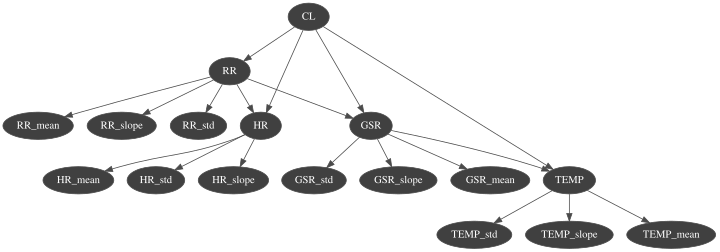

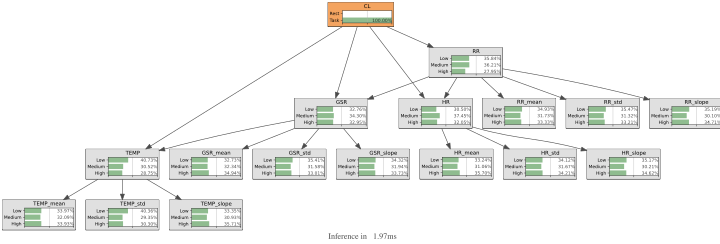

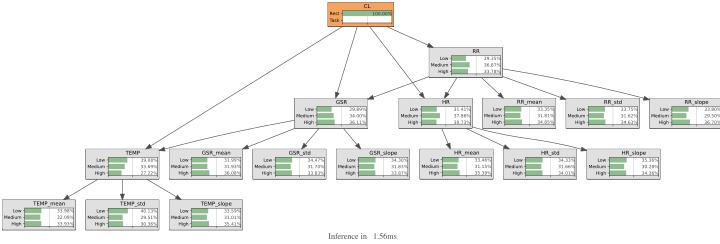

posterior type: <class 'pyagrum.pyagrum.Tensor'>
P(Rest): 0.4906575104058076
P(Task): 0.5093424895941925


In [66]:
import numpy as np
import pandas as pd
import pyagrum as gum
import pyagrum.lib.notebook as gnb

from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

STATE = ["Low", "Medium", "High"]
EPS = 1e-12

# ============================================================
# 0) (Optional) load strong rules from CSV
# ============================================================
# strong_task = pd.read_csv("strong_and_rules_task.csv")
# strong_rest = pd.read_csv("strong_and_rules_rest.csv")

# ============================================================
# 1) Parse rule -> conditions [(feat, state_idx)]
# ============================================================
def parse_rule_text(rule_text):
    """
    Expect: 'IF A is Low AND B is High THEN CL=Task'
    Return: [(A,0), (B,2)]
    """
    s = rule_text.strip()
    if "IF" in s:
        s = s.split("IF", 1)[1].strip()
    if "THEN" in s:
        s = s.split("THEN", 1)[0].strip()

    parts = [p.strip() for p in s.split("AND")]
    conds = []
    for p in parts:
        if " is " not in p:
            continue
        feat, st = [x.strip() for x in p.split(" is ", 1)]
        if st not in STATE:
            raise ValueError(f"Unknown state '{st}' in rule: {rule_text}")
        conds.append((feat, STATE.index(st)))
    return conds

def strong_features_from_rules(*dfs):
    feats = set()
    for df in dfs:
        for r in df["Rule"].tolist():
            for f,_ in parse_rule_text(r):
                feats.add(f)
    return sorted(list(feats))

STRONG_FEATURES = strong_features_from_rules(strong_task, strong_rest)
print("Strong features used as evidence:", STRONG_FEATURES)

# ============================================================
# 2) X_fuzzy -> beliefs per feature (normalize 3 states)
# ============================================================
def fuzzy_to_beliefs(X_fuzzy, columns, n_mf=3, eps=1e-6):
    beliefs = {}
    for i, feat in enumerate(columns):
        mu = X_fuzzy[:, i*n_mf:(i+1)*n_mf].copy()         # (N,3)
        mu = mu / (mu.sum(axis=1, keepdims=True) + eps)   # normalize
        # tránh 0 hoàn toàn
        mu = np.clip(mu, eps, 1.0)
        mu = mu / mu.sum(axis=1, keepdims=True)
        beliefs[feat] = mu
    return beliefs


# ============================================================
# 3) Group by sensor: HR -> {HR_mean, HR_std, HR_slope}, etc.
#    Build sensor beliefs from its 3 children (geometric mean across same state)
# ============================================================
def group_features_by_sensor(columns):
    groups = {}
    for feat in columns:
        sensor = feat.split("_")[0]  # TEMP_mean -> TEMP
        groups.setdefault(sensor, []).append(feat)
    # keep only sensors that have 3 features (mean/std/slope)
    groups = {k: sorted(v) for k,v in groups.items()}
    return groups

SENSOR_GROUPS = group_features_by_sensor(columns)
print("Sensor groups:", SENSOR_GROUPS)

def build_sensor_beliefs(feature_beliefs, sensor_groups, eps=1e-9):
    """
    feature_beliefs[feat]: (N,3)
    sensor_beliefs[sensor]: (N,3)
    Combine 3 child features using geometric mean per state:
      mu_sensor[s] ∝ (mu_f1[s] * mu_f2[s] * mu_f3[s])^(1/3)
    """
    sensor_beliefs = {}
    for sensor, feats in sensor_groups.items():
        # feats like [HR_mean, HR_slope, HR_std] (order doesn't matter)
        M = np.stack([feature_beliefs[f] for f in feats], axis=0)  # (K,N,3)
        # geometric mean across K features
        gm = np.exp(np.mean(np.log(M + eps), axis=0))              # (N,3)
        gm = gm / (gm.sum(axis=1, keepdims=True) + eps)
        sensor_beliefs[sensor] = gm
    return sensor_beliefs

# ============================================================
# 4) TAN edges between SENSORS using conditional MI I(Si;Sj|CL)
# ============================================================
def mi_from_joint(joint):
    pa = joint.sum(axis=1, keepdims=True)
    pb = joint.sum(axis=0, keepdims=True)
    ratio = (joint + EPS) / (pa @ pb + EPS)
    return float((joint * np.log(ratio + EPS)).sum())

def cond_mi_soft(belA, belB, y01, alpha=1.0):
    """
    belA, belB: (N,3) soft beliefs for two sensors
    y01: (N,) in {0,1}
    """
    y01 = np.asarray(y01).astype(int)
    total = 0.0
    for cls in [0,1]:
        mask = (y01 == cls)
        A = belA[mask]  # (Nc,3)
        B = belB[mask]  # (Nc,3)
        # expected joint counts
        joint_cnt = (A.T @ B) + alpha     # (3,3)
        joint = joint_cnt / (joint_cnt.sum() + EPS)
        Ic = mi_from_joint(joint)
        total += float(np.mean(y01==cls) * Ic)
    return float(total)

class DSU:
    def __init__(self, items):
        self.parent = {x:x for x in items}
        self.rank = {x:0 for x in items}
    def find(self, x):
        while self.parent[x]!=x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x
    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra==rb: return False
        if self.rank[ra] < self.rank[rb]:
            ra, rb = rb, ra
        self.parent[rb] = ra
        if self.rank[ra]==self.rank[rb]:
            self.rank[ra]+=1
        return True

def build_sensor_tan(sensor_beliefs, y01, alpha=1.0):
    sensors = list(sensor_beliefs.keys())
    edges = []
    for i in range(len(sensors)):
        for j in range(i+1, len(sensors)):
            a, b = sensors[i], sensors[j]
            w = cond_mi_soft(sensor_beliefs[a], sensor_beliefs[b], y01, alpha=alpha)
            edges.append((a,b,w))
    edges.sort(key=lambda x: -x[2])

    dsu = DSU(sensors)
    mst = []
    for a,b,w in edges:
        if dsu.union(a,b):
            mst.append((a,b,w))
        if len(mst)==len(sensors)-1:
            break

    # choose root by max incident weight sum
    adj = {s:[] for s in sensors}
    for a,b,w in mst:
        adj[a].append((b,w))
        adj[b].append((a,w))
    score = {s: sum(w for _,w in adj[s]) for s in sensors}
    root = max(sensors, key=lambda s: score[s])

    # direct tree by BFS
    parent = {root: None}
    q = [root]
    order = [root]
    while q:
        u = q.pop(0)
        for v,w in adj[u]:
            if v not in parent:
                parent[v] = u
                q.append(v)
                order.append(v)

    directed = []
    for v in order:
        if parent[v] is not None:
            directed.append((parent[v], v))
    return root, directed, mst

# ============================================================
# 5) Learn CPTs with soft counts
#    - P(Sensor | CL) or P(Sensor | CL, ParentSensor)
#    - P(Feature | Sensor)
# ============================================================
def learn_p_sensor_given_cl(sensor_beliefs, y01, alpha=1.0):
    y01 = np.asarray(y01).astype(int)
    cpt = {}
    for sensor, mu in sensor_beliefs.items():
        cpt[sensor] = {}
        for cls in [0,1]:
            mask = (y01 == cls)
            cnt = mu[mask].sum(axis=0) + alpha
            cpt[sensor][cls] = cnt / (cnt.sum() + EPS)
    return cpt

def learn_p_childsensor_given_cl_parent(sensor_beliefs, y01, parent, child, alpha=1.0):
    """
    return probs[cl, parent_state, child_state] shape (2,3,3)
    """
    y01 = np.asarray(y01).astype(int)
    P = sensor_beliefs[parent]  # (N,3)
    C = sensor_beliefs[child]   # (N,3)
    probs = np.zeros((2,3,3), dtype=float)

    for cl in [0,1]:
        mask = (y01==cl)
        PP = P[mask]
        CC = C[mask]
        for ps in range(3):
            w = PP[:, ps]  # (Nc,)
            cnt = (w[:, None] * CC).sum(axis=0) + alpha  # (3,)
            probs[cl, ps] = cnt / (cnt.sum() + EPS)
    return probs

def learn_p_feature_given_sensor(feature_beliefs, sensor_beliefs, sensor_groups, alpha=1.0):
    """
    return dict feature -> probs[sensor_state, feature_state] shape (3,3)
    """
    out = {}
    for sensor, feats in sensor_groups.items():
        muS = sensor_beliefs[sensor]  # (N,3)
        for feat in feats:
            muF = feature_beliefs[feat]  # (N,3)
            table = np.zeros((3,3), dtype=float)
            for ss in range(3):
                w = muS[:, ss]  # (N,)
                cnt = (w[:, None] * muF).sum(axis=0) + alpha
                table[ss] = cnt / (cnt.sum() + EPS)
            out[feat] = table
    return out

# ============================================================
# 6) Build BN structure: CL -> sensors; sensor TAN edges; sensor -> its features
# ============================================================
def build_bn_from_soft(
    columns,
    sensor_groups,
    tan_root, tan_edges,
    priors,
    cpt_sensor_root,          # P(sensor|CL) for all sensors
    cpt_sensor_child_dict,    # (parent,child) -> probs[cl,ps,cs]
    cpt_feat_given_sensor     # feature -> table[ss,fs]
):
    bn = gum.BayesNet("FuzzyBN_Sensor_TAN")

    # CL
    vcl = gum.LabelizedVariable("CL", "CognitiveLoad", 2)
    vcl.changeLabel(0, "Rest")
    vcl.changeLabel(1, "Task")
    bn.add(vcl)
    bn.cpt("CL").fillWith([float(priors[0]), float(priors[1])])

    # Sensors
    for sensor in sensor_groups.keys():
        v = gum.LabelizedVariable(sensor, sensor, 3)
        v.changeLabel(0, "Low"); v.changeLabel(1, "Medium"); v.changeLabel(2, "High")
        bn.add(v)
        bn.addArc("CL", sensor)

    # TAN arcs among sensors
    for src, dst in tan_edges:
        bn.addArc(src, dst)

    # Sensor CPTs
    for sensor in sensor_groups.keys():
        parents = [bn.variable(p).name() for p in bn.parents(sensor)]
        sensor_parents = [p for p in parents if p != "CL"]

        if len(sensor_parents)==0:
            # P(sensor_state | CL)
            bn.cpt(sensor)[{"CL":0}] = list(np.array(cpt_sensor_root[sensor][0], float))
            bn.cpt(sensor)[{"CL":1}] = list(np.array(cpt_sensor_root[sensor][1], float))
        else:
            # exactly 1 TAN parent
            p = sensor_parents[0]
            probs = cpt_sensor_child_dict[(p, sensor)]  # (2,3,3)
            for cl in [0,1]:
                for ps in [0,1,2]:
                    bn.cpt(sensor)[{"CL":cl, p:ps}] = list(probs[cl, ps])

    # Feature nodes (12)
    for feat in columns:
        v = gum.LabelizedVariable(feat, feat, 3)
        v.changeLabel(0, "Low"); v.changeLabel(1, "Medium"); v.changeLabel(2, "High")
        bn.add(v)

        sensor = feat.split("_")[0]
        bn.addArc(sensor, feat)

        # CPT P(feat | sensor)
        table = cpt_feat_given_sensor[feat]  # (3,3)
        for ss in [0,1,2]:
            bn.cpt(feat)[{sensor:ss}] = list(np.array(table[ss], float))

    return bn

# ============================================================
# 7) Inference: compute P(Task) with soft evidence on selected features
# ============================================================
def p_task_from_bn(bn, feature_beliefs, columns, use_features, engine="LazyPropagation"):
    """
    return p_task: (N,)
    """
    N = feature_beliefs[columns[0]].shape[0]

    ie = gum.LazyPropagation(bn) if engine == "LazyPropagation" else gum.ShaferShenoyInference(bn)

    p_task = np.zeros(N, dtype=float)

    for i in range(N):
        ie.eraseAllEvidence()

        # soft evidence (likelihoods)
        for feat in use_features:
            ie.addEvidence(feat, list(feature_beliefs[feat][i].astype(float)))

        ie.makeInference()

        post = ie.posterior("CL")  # gum.Potential

        # CÁCH 1 (ổn định nhất): lấy theo state index
        p_task[i] = float(post[{"CL": 1}])   # 1 = Task
        # p_rest  = float(post[{"CL": 0}])   # 0 = Rest

        # (Optional sanity check)
        # if abs((p_rest + p_task[i]) - 1.0) > 1e-6:
        #     print("Warning: posterior not normalized", p_rest, p_task[i])

    return p_task


# ============================================================
# 8) Train BN on (X_fuzzy,y) => returns bn + (p_task on given set)
# ============================================================
def fit_bn_and_predict(Xtr_fuzzy_fold, ytr_fold, Xva_fuzzy_fold, columns,
                       sensor_groups, evidence_features, alpha=1.0):
    # beliefs
    feat_bel_tr = fuzzy_to_beliefs(Xtr_fuzzy_fold, columns)
    feat_bel_va = fuzzy_to_beliefs(Xva_fuzzy_fold, columns)

    # sensor beliefs
    sen_bel_tr = build_sensor_beliefs(feat_bel_tr, sensor_groups)

    # TAN on sensors
    root, tan_edges, _ = build_sensor_tan(sen_bel_tr, ytr_fold, alpha=alpha)

    # priors
    priors = {0: float(np.mean(np.asarray(ytr_fold)==0)),
              1: float(np.mean(np.asarray(ytr_fold)==1))}

    # CPTs
    cpt_sensor_root = learn_p_sensor_given_cl(sen_bel_tr, ytr_fold, alpha=alpha)

    cpt_sensor_child_dict = {}
    for (p, c) in tan_edges:
        probs = learn_p_childsensor_given_cl_parent(sen_bel_tr, ytr_fold, p, c, alpha=alpha)
        cpt_sensor_child_dict[(p,c)] = probs

    cpt_feat_given_sensor = learn_p_feature_given_sensor(feat_bel_tr, sen_bel_tr, sensor_groups, alpha=alpha)

    # build BN
    bn = build_bn_from_soft(columns, sensor_groups, root, tan_edges, priors,
                            cpt_sensor_root, cpt_sensor_child_dict, cpt_feat_given_sensor)

    # inference on val
    p_task = p_task_from_bn(bn, feat_bel_va, columns, evidence_features)
    return bn, p_task

# ============================================================
# 9) GROUPKFOLD ON TRAIN
# ============================================================
def eval_groupkfold_bn(Xtr_fuzzy, y_train, user_train, columns,
                       sensor_groups, evidence_features,
                       n_splits=5, alpha=1.0):
    gkf = GroupKFold(n_splits=n_splits)
    rows = []

    y_train = np.asarray(y_train).astype(int)
    groups = np.asarray(user_train)

    for fold, (tr, va) in enumerate(gkf.split(Xtr_fuzzy, y_train, groups), start=1):
        _, p_task = fit_bn_and_predict(
            Xtr_fuzzy[tr], y_train[tr],
            Xtr_fuzzy[va], columns,
            sensor_groups, evidence_features,
            alpha=alpha
        )

        y_true = y_train[va]
        y_pred = (p_task >= 0.5).astype(int)

        acc = accuracy_score(y_true, y_pred)
        f1  = f1_score(y_true, y_pred)
        auc = roc_auc_score(y_true, p_task)

        # Brier score
        brier = float(np.mean((p_task - y_true)**2))

        rows.append({"fold": fold, "acc": acc, "f1": f1, "auc": auc, "brier": brier})
        print(f"[Fold {fold}] acc={acc:.3f} f1={f1:.3f} auc={auc:.3f} brier={brier:.3f}")

    df = pd.DataFrame(rows)
    print("\nCV mean:")
    display(df.mean(numeric_only=True))
    return df

# Choose evidence set:
# - chỉ dùng strong features => ít nhiễu, “đúng ý strong rules”
# - hoặc dùng all features => baseline đầy đủ
USE_ONLY_STRONG = True
EVIDENCE_FEATURES = STRONG_FEATURES if USE_ONLY_STRONG else columns
print("Evidence features:", EVIDENCE_FEATURES)

cv_df = eval_groupkfold_bn(
    Xtr_fuzzy_n, y_train, user_train, columns,
    SENSOR_GROUPS, EVIDENCE_FEATURES,
    n_splits=5, alpha=1.0
)

# ============================================================
# 10) FINAL: Train on ALL TRAIN -> Evaluate on HELD-OUT TEST
# ============================================================
bn_final, p_task_test = fit_bn_and_predict(
    Xtr_fuzzy_n, np.asarray(y_train).astype(int),
    Xte_fuzzy_n, columns,
    SENSOR_GROUPS, EVIDENCE_FEATURES,
    alpha=1.0
)

y_test = np.asarray(y_test).astype(int)
y_pred_test = (p_task_test >= 0.5).astype(int)

acc = accuracy_score(y_test, y_pred_test)
f1  = f1_score(y_test, y_pred_test)
auc = roc_auc_score(y_test, p_task_test)
brier = float(np.mean((p_task_test - y_test)**2))

print("\nFINAL TEST:")
print("Accuracy:", acc)
print("F1:", f1)
print("AUC:", auc)
print("Brier:", brier)
print("Confusion matrix:\n", pd.crosstab(y_test, y_pred_test, rownames=["True"], colnames=["Pred"]))

# ============================================================
# 11) Visualize BN like your example
# ============================================================
gnb.showBN(bn_final, size="10")
gnb.showInference(bn_final, evs={"CL":"Task"}, size="10")
gnb.showInference(bn_final, evs={"CL":"Rest"}, size="10")

# Optional: show inference with soft evidence of 1 test sample
# (pyAgrum notebook widget sometimes doesn't accept soft evidence in gnb.showInference,
#  so we'll just print posterior computed by engine)
def debug_one_sample_soft(bn, X_fuzzy, columns, evidence_features, idx=0):

    ie = gum.LazyPropagation(bn_final)
    ie.eraseAllEvidence()
    
    # giả lập soft evidence của sample 0
    bel = fuzzy_to_beliefs(X_fuzzy, columns)
    for feat in EVIDENCE_FEATURES:
        ie.addEvidence(feat, list(bel[feat][0].astype(float)))
    
    ie.makeInference()
    post = ie.posterior("CL")
    print("posterior type:", type(post))
    print("P(Rest):", float(post[{"CL":0}]))
    print("P(Task):", float(post[{"CL":1}]))


debug_one_sample_soft(bn_final, Xte_fuzzy_n, columns, EVIDENCE_FEATURES, idx=0)


với dữ liệu dataset hiện tại thu thập được thì ước tính khả năng Task ~51%, Rest ~49% → Task nhỉnh hơn


* P(Task) ≈ 51%, P(Rest) ≈ 49% → Task nhỉnh hơn
* Nhưng chênh lệch rất nhỏ (~2%) → mô hình chưa quá chắc chắn
* Nghĩa là luật / dữ liệu hiện tại chỉ hơi nghiêng về Task, vẫn còn khả năng Rest khá cao


# **KẾT QUẢ**

**CV mean:**

Accuracy: 0.627 → ~63% mẫu dự đoán đúng trung bình

F1: 0.617 → cân bằng precision/recall, trung bình khá

AUC: 0.650 → khả năng phân biệt Task vs Rest khoảng 65%

Brier: 0.248 → mức độ lỗi dự đoán xác suất trung bình, càng thấp càng tốt

**Đánh giá tập test**
Accuracy 0.674 (~67%) → ~2/3 dự đoán đúng.

F1 0.670 (~67%) → cân bằng giữa precision và recall, khá tốt.

AUC 0.695 (~70%) → mô hình phân biệt Task vs Rest ở mức khá.

Brier 0.246 → độ lỗi xác suất nhỏ, mô hình dự đoán xác suất khá ổn.

**Confusion matrix:**

True negative (TN) = 66 → Rest dự đoán đúng

False positive (FP) = 29 → Rest nhầm thành Task

False negative (FN) = 34 → Task nhầm thành Rest

True positive (TP) = 64 → Task dự đoán đúng

**Nhận xét:**

Mô hình nhỉnh hơn trong dự đoán Task (TP=64) so với Rest (TN=66/95 ~69%)

# =================== // ============================

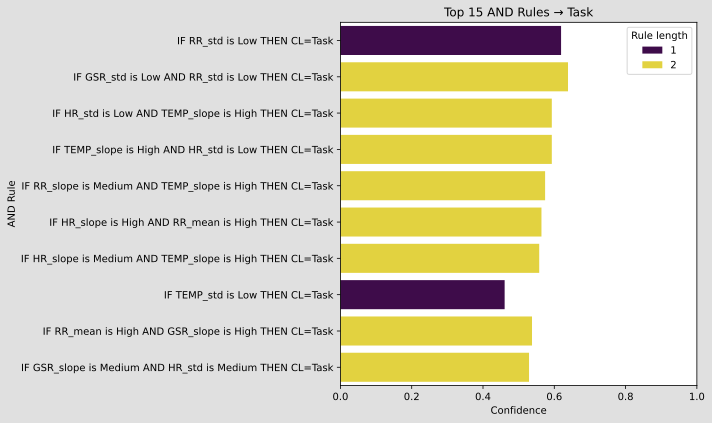

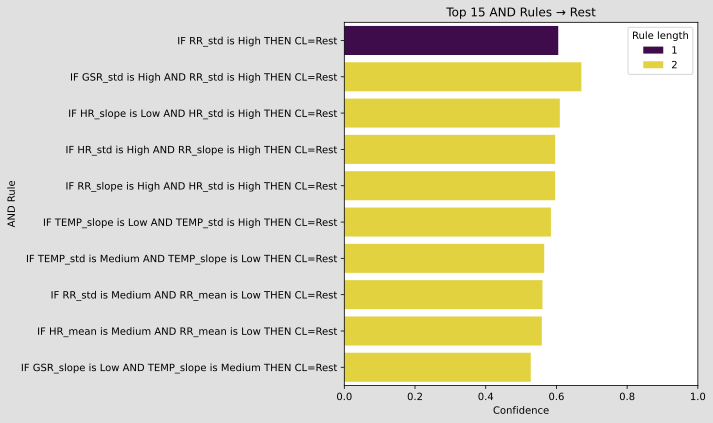

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_and_rules_bar(df, title):
    plt.figure(figsize=(10, 6))
    sns.barplot(
        data=df,
        y="Rule",
        x="Confidence",
        hue="Len",
        dodge=False,
        palette="viridis"
    )
    plt.title(title)
    plt.xlabel("Confidence")
    plt.ylabel("AND Rule")
    plt.xlim(0, 1)
    plt.legend(title="Rule length")
    plt.tight_layout()
    plt.show()

# Task
plot_and_rules_bar(
    and_task.head(15),
    "Top 15 AND Rules → Task"
)

# Rest
plot_and_rules_bar(
    and_rest.head(15),
    "Top 15 AND Rules → Rest"
)


In [69]:
# 1) Xuất riêng 2 file
and_task.head(15).to_csv("top15_and_task_rules.csv", index=False, encoding="utf-8-sig")
and_rest.head(15).to_csv("top15_and_rest_rules.csv", index=False, encoding="utf-8-sig")

print("Saved: top15_and_task_rules.csv")
print("Saved: top15_and_rest_rules.csv")


# 2) (Tuỳ chọn) Gộp chung 1 file để tiện report
and_task_15 = and_task.head(15).copy()
and_task_15["Target"] = "Task"

and_rest_15 = and_rest.head(15).copy()
and_rest_15["Target"] = "Rest"

and_both_15 = pd.concat([and_task_15, and_rest_15], ignore_index=True)
and_both_15.to_csv("top15_and_rules_both.csv", index=False, encoding="utf-8-sig")

print("Saved: top15_and_rules_both.csv")


Saved: top15_and_task_rules.csv
Saved: top15_and_rest_rules.csv
Saved: top15_and_rules_both.csv


In [70]:
read=pd.read_csv('/kaggle/working/top15_and_rules_both.csv')
print(read)
print(read.shape)

                                                 Rule  Len  Support_AND  \
0                       IF RR_std is Low THEN CL=Task    1   218.849113   
1    IF GSR_std is Low AND RR_std is Low THEN CL=Task    2    86.236631   
2   IF HR_std is Low AND TEMP_slope is High THEN C...    2    78.178612   
3   IF TEMP_slope is High AND HR_std is Low THEN C...    2    78.178612   
4   IF RR_slope is Medium AND TEMP_slope is High T...    2    67.203924   
5   IF HR_slope is High AND RR_mean is High THEN C...    2    69.453138   
6   IF HR_slope is Medium AND TEMP_slope is High T...    2    67.842426   
7                     IF TEMP_std is Low THEN CL=Task    1   133.203070   
8   IF RR_mean is High AND GSR_slope is High THEN ...    2    73.468764   
9   IF GSR_slope is Medium AND HR_std is Medium TH...    2    63.790378   
10                     IF RR_std is High THEN CL=Rest    1   214.449552   
11  IF GSR_std is High AND RR_std is High THEN CL=...    2    78.748240   
12  IF HR_slope is Low AN

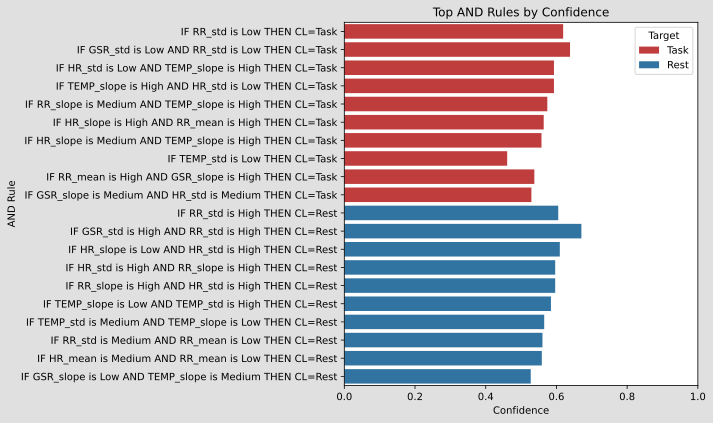

In [71]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/kaggle/working/top15_and_rules_both.csv")

plt.figure(figsize=(10, 6))
sns.barplot(
    data=df,
    y="Rule",
    x="Confidence",
    hue="Target",
    dodge=False,
    palette={"Task": "tab:red", "Rest": "tab:blue"}
)

plt.title("Top AND Rules by Confidence")
plt.xlabel("Confidence")
plt.ylabel("AND Rule")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()


# ==================
# ====================

 # ============================= 